# Task 2 — Time-Series Regression: Prediksi Remaining Useful Life (RUL) Mesin Press

**Proyek UTS Deep Learning:** *Hands-on Deep Learning: Classification, Regression, and Clustering*
**Identitas:** Task 2 — Time-Series Regression · PIC: Anggota 2
**Notebook:** `task2_time_series_regression.ipynb` (satu file, dapat dijalankan dengan *Run All*, di PC lokal maupun Colab)

---

# SECTION 1 — Project Overview

## Tujuan
Memprediksi **Remaining Useful Life (RUL)**, yaitu jumlah siklus yang tersisa sampai sebuah mesin press rusak, berdasarkan log sensor dan pengaturan operasi per siklus. Prediksi dibuat pada **siklus terakhir tiap unit di data uji** (data uji berhenti pada titik acak sebelum mesin rusak).

## Data (sesuai kamus data)
| Berkas | Isi |
|---|---|
| `rul_train.csv.gz` | Riwayat penuh sampai mesin rusak (siklus terakhir = siklus rusak). Label RUL dihitung sendiri. |
| `rul_test.csv.gz` | Riwayat terpotong di titik acak sebelum rusak. Label tidak dibagikan. |

Kolom: `id_unit`, `siklus`, `setel_1..3` (pengaturan operasi), `s01..s21` (sensor; `NaN` = bacaan hilang).
Label: RUL = (siklus rusak − siklus saat ini), **dipotong maksimal 150**.

## Ringkasan metode
1. **EDA** untuk memahami regime operasi, sensor informatif/tidak informatif, NaN, dan spike.
2. **Preprocessing tanpa leakage:** statistik normalisasi dihitung per regime operasi hanya dari unit latih; spike dibuang lalu diimputasi kausal (hanya memakai masa lalu).
3. **Pelabelan RUL** (cap 150) dan **seleksi sensor** berdasarkan korelasi dengan RUL pada unit latih.
4. **Sliding window** (panjang urutan tetap) dengan **pembagian train/validasi per ID mesin**.
5. **Model:** baseline non-DL (Ridge dan Gradient Boosting pada fitur ringkasan window) vs dua model sekuens PyTorch (**LSTM** dan **CNN-1D dilasi**).
6. **Metrik:** RMSE dan *asymmetric score* (menghukum prediksi terlalu optimistis lebih berat).
7. **Ketidakpastian:** prediction interval dengan MC-Dropout yang dikalibrasi.

# SECTION 2 — Library Installation & Import

In [24]:
# Instalasi hanya jika library belum ada. Di PC lokal, jika ingin GPU NVIDIA, pasang PyTorch versi CUDA lebih dulu
# (lihat https://pytorch.org/get-started/locally/), lalu jalankan notebook ini. Tanpa itu, pip memasang versi default.
import importlib, subprocess, sys

for pkg, mod in [("torch", "torch"), ("scikit-learn", "sklearn"), ("pandas", "pandas"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"Memasang {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [25]:
import os, re, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# ---- Random seed (reproducibility) ----
SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

# ---- Device (GPU jika tersedia) ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (training DL lebih lambat; di PC tanpa GPU, kecilkan EPOCHS di Section 3, mis. 15)")

PyTorch : 2.15.0+cpu
Device  : cpu | CPU (training DL lebih lambat; di PC tanpa GPU, kecilkan EPOCHS di Section 3, mis. 15)


# SECTION 3 — Configuration & Dataset Loading

Notebook mencari folder `dataset` di folder tempat notebook disimpan (atau satu tingkat di atasnya `../dataset`).
**Di PC lokal:** letakkan `task2_time_series_regression.ipynb` sejajar dengan folder `dataset` yang berisi `rul_train.csv.gz` dan `rul_test.csv.gz`, lalu buka dari folder itu.
Bagian khusus Google Colab (unggah file / mount Drive) hanya aktif jika notebook terdeteksi berjalan di Colab.

In [26]:
# ---------------- KONFIGURASI (semua hyperparameter terpusat di sini) ----------------
CANDIDATE_DIRS = ["dataset", "../dataset", "/content/dataset", "/content/drive/MyDrive/dataset", "."]   # relatif terhadap lokasi notebook
TRAIN_FILE, TEST_FILE = "rul_train.csv.gz", "rul_test.csv.gz"

RUL_CAP        = 150      # RUL dipotong maksimal 150 siklus (instruksi dosen)
SEQ_LEN        = 30       # panjang sliding window (siklus)
VAL_FRAC       = 0.20     # porsi UNIT (bukan baris) untuk validasi
N_REGIMES      = 6        # jumlah regime operasi (dikonfirmasi di EDA)
SPIKE_Z        = 5.0      # |z| > 5 (setelah normalisasi per regime) dianggap spike
SELECT_RHO     = 0.10     # ambang |Spearman| sensor vs RUL untuk seleksi fitur
BATCH_SIZE     = 512
EPOCHS         = 40
LR             = 1e-3
PATIENCE       = 8        # early stopping
MC_SAMPLES     = 30       # jumlah forward pass MC-Dropout
INTERVAL_LEVEL = 0.90     # tingkat prediction interval
OUTPUT_DIR     = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
CSV_NAME       = "prediksi_rul.csv"

USE_GOOGLE_DRIVE = False   # ubah ke True jika folder dataset Anda ada di Google Drive (MyDrive/dataset)
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

def find_data_dir():
    for d in CANDIDATE_DIRS:
        if (Path(d) / TRAIN_FILE).exists() and (Path(d) / TEST_FILE).exists():
            return Path(d)
    return None

DATA_DIR = find_data_dir()
if DATA_DIR is None:
    try:                                   # fallback Colab: unggah manual
        from google.colab import files
        print("Folder dataset tidak ditemukan. Unggah rul_train.csv.gz dan rul_test.csv.gz:")
        Path("dataset").mkdir(exist_ok=True)
        for name, content in files.upload().items():
            (Path("dataset") / name).write_bytes(content)
        DATA_DIR = find_data_dir()
    except ImportError:
        pass
assert DATA_DIR is not None, f"{TRAIN_FILE} / {TEST_FILE} tidak ditemukan. Cek CANDIDATE_DIRS."
print("DATA_DIR =", DATA_DIR.resolve())

# ---- Struktur folder ----
for root, _, fnames in os.walk(DATA_DIR):
    depth = Path(root).relative_to(DATA_DIR).parts
    if len(depth) > 1: continue
    print(f"{root}/")
    for f in sorted(fnames):
        print(f"   {f:<28s} {os.path.getsize(os.path.join(root, f)) / 1e6:8.2f} MB")

DATA_DIR = D:\TELKOM\Semester 7\DL\UTS\dataset
..\dataset/
   clustering.npz                 130.26 MB
   clustering_meta.csv              0.60 MB
   kamus_data.md                    0.00 MB
   klasifikasi_test.npz            61.10 MB
   klasifikasi_test_meta.csv        0.48 MB
   klasifikasi_train.npz          179.29 MB
   klasifikasi_train_meta.csv       1.82 MB
   rul_test.csv.gz                  4.13 MB
   rul_train.csv.gz                20.34 MB


In [27]:
train_df = pd.read_csv(DATA_DIR / TRAIN_FILE)
test_df  = pd.read_csv(DATA_DIR / TEST_FILE)

# Nama kolom diambil dari data (bukan ditebak) dan divalidasi terhadap kamus data
ID_COL, CYCLE_COL = "id_unit", "siklus"
SETTINGS = [c for c in train_df.columns if re.fullmatch(r"setel_\d", c)]
SENSORS  = [c for c in train_df.columns if re.fullmatch(r"s\d\d", c)]
assert SETTINGS == ["setel_1", "setel_2", "setel_3"] and len(SENSORS) == 21
assert list(train_df.columns) == list(test_df.columns), "Kolom train dan test berbeda!"

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("\nTipe data (train):"); print(train_df.dtypes.value_counts().to_string())
print("\nKolom:", list(train_df.columns))

for name, d in [("train", train_df), ("test", test_df)]:
    g = d.groupby(ID_COL)[CYCLE_COL].agg(["min", "max", "count"])
    print(f"\n[{name}] unit={d[ID_COL].nunique()} | baris={len(d)} | "
          f"siklus/unit: min={g['count'].min()}, rata-rata={g['count'].mean():.1f}, max={g['count'].max()}")
    print(f"   siklus mulai dari 1 semua unit : {(g['min'] == 1).all()}")
    print(f"   siklus berurutan tanpa lompatan: {(g['max'] - g['min'] + 1 == g['count']).all()}")
    print(f"   duplikat (unit, siklus)        : {d.duplicated([ID_COL, CYCLE_COL]).sum()}")
    print(f"   terurut menurut (unit, siklus) : {d.sort_values([ID_COL, CYCLE_COL]).index.equals(d.index)}")

overlap = set(train_df[ID_COL]) & set(test_df[ID_COL])
print("\nID unit yang muncul di train DAN test:", len(overlap), "(harus 0)")
train_df.head(3)

Train: (254174, 26) | Test: (51692, 26)

Tipe data (train):
float64    24
int64       2

Kolom: ['id_unit', 'siklus', 'setel_1', 'setel_2', 'setel_3', 's01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']

[train] unit=900 | baris=254174 | siklus/unit: min=133, rata-rata=282.4, max=778
   siklus mulai dari 1 semua unit : True
   siklus berurutan tanpa lompatan: True
   duplikat (unit, siklus)        : 0
   terurut menurut (unit, siklus) : True

[test] unit=300 | baris=51692 | siklus/unit: min=50, rata-rata=172.3, max=455
   siklus mulai dari 1 semua unit : True
   siklus berurutan tanpa lompatan: True
   duplikat (unit, siklus)        : 0
   terurut menurut (unit, siklus) : True

ID unit yang muncul di train DAN test: 0 (harus 0)


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,3,1,20.001,0.7005,100.0,1107.746,569.289,991.700,1099.533,NaN,1313.240,725.325,778.517,499.195,782.886,1495.906,1092.248,1144.779,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003
1,3,2,34.996,0.8424,100.0,1071.040,587.821,1013.673,NaN,157.684,1304.796,729.707,776.236,452.236,819.193,1492.101,1095.511,1167.320,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368
2,3,3,0.001,-0.0012,100.0,1130.132,585.094,998.221,1127.436,161.918,1314.296,725.847,783.364,533.958,829.940,1505.026,1091.245,1170.340,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443


# SECTION 4 — Exploratory Data Analysis

Analisis di section ini bersifat **eksploratif**. Statistik yang dipakai untuk model (normalisasi, seleksi sensor)
dihitung ulang di Section 5–6 **hanya dari unit latih**.

## 4.1 Distribusi umur mesin (train) dan titik potong (test)

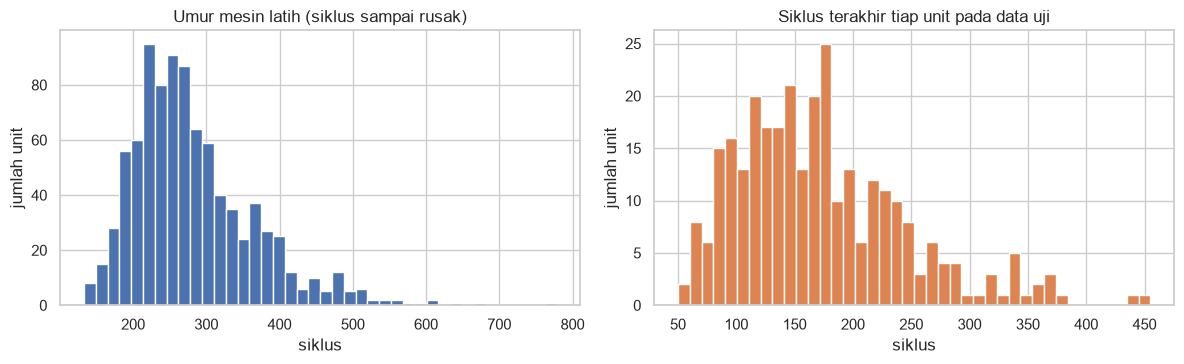

       umur_train  cut_test
count       900.0     300.0
mean        282.4     172.3
std          84.6      72.7
min         133.0      50.0
25%         224.0     117.0
50%         265.0     162.5
75%         323.0     212.0
max         778.0     455.0


In [28]:
life = train_df.groupby(ID_COL)[CYCLE_COL].max()      # umur mesin latih (siklus saat rusak)
cut  = test_df.groupby(ID_COL)[CYCLE_COL].max()       # titik potong data uji

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(life, bins=40, color="#4c72b0"); ax[0].set_title("Umur mesin latih (siklus sampai rusak)")
ax[1].hist(cut,  bins=40, color="#dd8452"); ax[1].set_title("Siklus terakhir tiap unit pada data uji")
for a in ax: a.set_xlabel("siklus"); a.set_ylabel("jumlah unit")
plt.tight_layout(); plt.show()
print(pd.concat([life.describe().round(1).rename("umur_train"), cut.describe().round(1).rename("cut_test")], axis=1))

**Interpretasi.** Umur mesin latih sangat bervariasi (dari ratusan hingga lebih dari 700 siklus) dan miring ke kanan, sehingga
satu angka "umur normal" tidak bisa dipakai; model harus membaca kondisi mesin dari sensor. Data uji terpotong rata-rata di siklus ke-172 (vs umur latih rata-rata 282), sehingga banyak unit uji kemungkinan masih jauh dari kerusakan (RUL tinggi,
banyak yang mendekati batas 150). Konsekuensinya, kemampuan membedakan "masih sehat" dari "mulai menurun" sama pentingnya dengan akurasi di dekat kerusakan.

## 4.2 Operating settings (`setel_1..3`)

Jumlah kombinasi unik (dibulatkan): 6
       setel_1        setel_2        setel_3           n
          mean    std    mean    std    mean  std       
_reg                                                    
100        0.0  0.002    0.00  0.002   100.0  0.0  42393
100100    10.0  0.002    0.25  0.002   100.0  0.0  42078
201100    20.0  0.002    0.70  0.002   100.0  0.0  42600
251060    25.0  0.002    0.62  0.002    60.0  0.0  42211
351100    35.0  0.002    0.84  0.002   100.0  0.0  42252
421100    42.0  0.002    0.84  0.002   100.0  0.0  42640


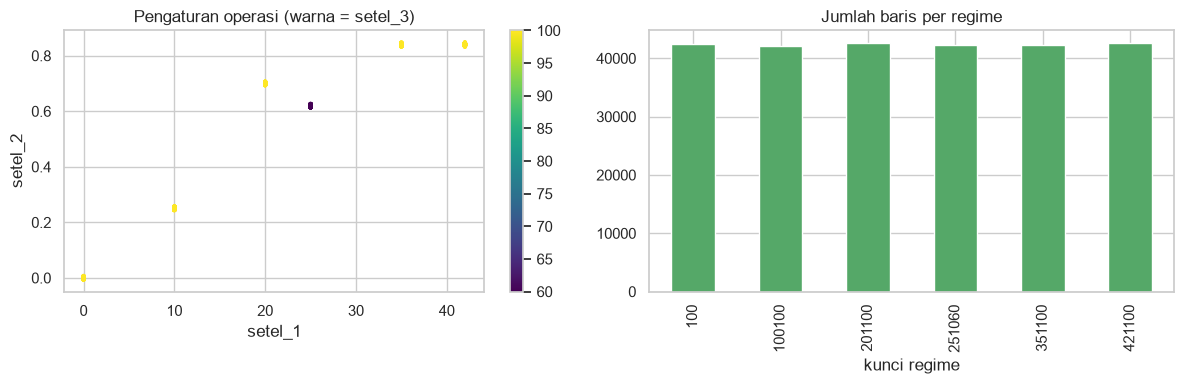

In [29]:
def quick_regime(df):
    # Kunci regime sederhana untuk EDA: pembulatan pengaturan operasi
    r = df[SETTINGS].round(0).astype(int)
    return r["setel_1"] * 10000 + r["setel_2"] * 1000 + r["setel_3"]

train_df["_reg"] = quick_regime(train_df)
print("Jumlah kombinasi unik (dibulatkan):", train_df["_reg"].nunique())
print(train_df.groupby("_reg")[SETTINGS].agg(["mean", "std"]).round(3).assign(n=train_df.groupby("_reg").size()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
samp = train_df.sample(20000, random_state=SEED)
sc = ax[0].scatter(samp["setel_1"], samp["setel_2"], c=samp["setel_3"], s=4, cmap="viridis")
ax[0].set(xlabel="setel_1", ylabel="setel_2", title="Pengaturan operasi (warna = setel_3)"); plt.colorbar(sc, ax=ax[0])
train_df.groupby("_reg").size().plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("Jumlah baris per regime"); ax[1].set_xlabel("kunci regime")
plt.tight_layout(); plt.show()

**Interpretasi.** Pengaturan operasi **bukan kontinu**: ia hanya mengambil **6 kombinasi diskret** (dengan derau kecil di sekitar tiap pusat),
dengan jumlah baris hampir sama per regime. Jadi `setel_1..3` pada dasarnya adalah **penanda regime operasi**, bukan sinyal degradasi.
Ini penting karena nilai sensor sangat bergantung pada regime (dibuktikan di 4.3), sehingga regime harus dinormalkan.

## 4.3 Karakteristik sensor

        count     mean    std      min      max
s01  249093.0  1101.65  17.76  1042.70  1161.24
s02  248902.0   579.60  15.93   537.79   619.76
s03  249058.0  1005.49  23.05   943.02  1081.73
s04  248959.0  1133.48  17.62  1079.08  1196.05
s05  249065.0   168.54   9.49   156.90   187.16
s06  248939.0  1310.54   8.69  1267.15  1358.94
s07  248955.0   723.63   6.83   683.14   754.71
s08  249044.0   779.35   6.86   750.19   810.49
s09  249001.0   498.01  25.16   444.32   543.87
s10  249036.0   803.32  17.42   771.55   839.65
s11  249137.0  1492.43  16.13  1420.98  1559.76
s12  248981.0  1099.56   6.30  1084.72  1116.85
s13  249012.0  1172.39  26.33  1085.90  1250.48
s14  249114.0  1339.62  15.78  1278.02  1395.82
s15  249036.0   878.64   8.30   843.48   925.06
s16  249088.0   802.28  23.94   754.02   877.37
s17  249064.0   388.27  11.51   354.54   419.11
s18  248939.0   984.69  30.52   926.59  1035.74
s19  249018.0   841.10  21.92   806.66   890.63
s20  248803.0  1013.82  45.43   932.58  

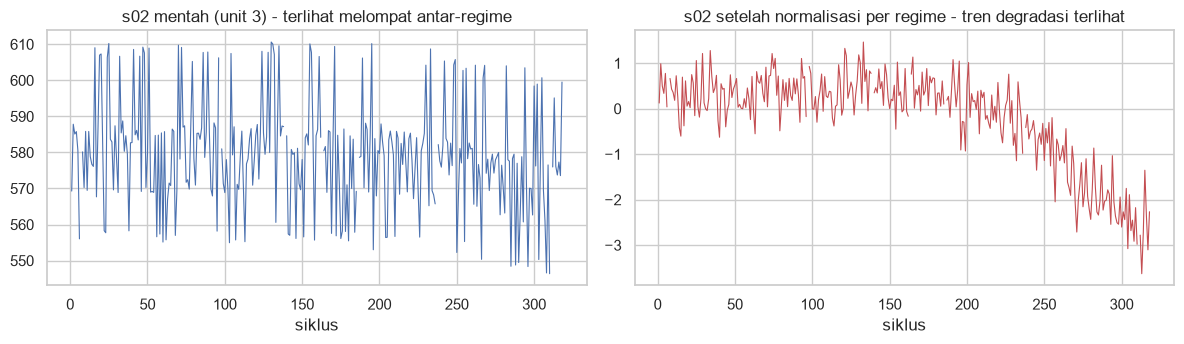


Proporsi varians sensor yang dijelaskan regime (eta^2):
s01    0.941
s02    0.960
s03    0.916
s04    0.862
s05    1.000
s06    0.755
s07    0.503
s08    0.692
s09    0.996
s10    0.993
s11    0.374
s12    0.934
s13    0.897
s14    0.842
s15    0.413
s16    0.982
s17    0.940
s18    0.996
s19    0.998
s20    0.991
s21    0.999


In [30]:
print(train_df[SENSORS].describe().T[["count", "mean", "std", "min", "max"]].round(2).to_string())

# Seberapa besar variasi sensor dijelaskan oleh regime saja? (eta^2 = 1 - varians dalam regime / varians total)
tot_var = train_df[SENSORS].var()
within  = train_df.groupby("_reg")[SENSORS].var().mul(train_df.groupby("_reg").size(), axis=0).sum() / len(train_df)
eta2 = (1 - within / tot_var).rename("eta2_regime")

# z-score per regime (HANYA untuk EDA; versi tanpa leakage ada di Section 5)
mu_e = train_df.groupby("_reg")[SENSORS].transform("mean")
sd_e = train_df.groupby("_reg")[SENSORS].transform("std")
Z = (train_df[SENSORS] - mu_e) / sd_e

# Contoh satu unit: sensor mentah vs sensor ternormalisasi regime
u0 = train_df[ID_COL].iloc[0]
m0 = train_df[ID_COL] == u0
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(train_df.loc[m0, CYCLE_COL], train_df.loc[m0, "s02"], lw=0.8); ax[0].set_title(f"s02 mentah (unit {u0}) - terlihat melompat antar-regime")
ax[1].plot(train_df.loc[m0, CYCLE_COL], Z.loc[m0, "s02"], lw=0.8, color="#c44e52"); ax[1].set_title("s02 setelah normalisasi per regime - tren degradasi terlihat")
for a in ax: a.set_xlabel("siklus")
plt.tight_layout(); plt.show()
print("\nProporsi varians sensor yang dijelaskan regime (eta^2):"); print(eta2.round(3).to_string())

**Interpretasi.** Sebagian besar sensor didominasi regime (15 dari 21 sensor memiliki eta² di atas 0,85): nilai mentah lebih banyak mencerminkan
*pengaturan operasi* daripada *kondisi mesin*. Pada grafik contoh, sensor mentah melompat-lompat antar-regime dan menyembunyikan
tren; setelah dinormalkan **per regime**, pola degradasi menjadi jelas. Karena itu normalisasi global (satu mean/std untuk semua baris) akan keliru; normalisasi harus per regime.

## 4.4 Identifikasi sensor tidak informatif
Uji tanpa label: untuk tiap unit, bandingkan rata-rata sensor ternormalisasi pada **20% siklus awal** vs **20% siklus akhir** umurnya.
Sensor yang tidak berubah sepanjang umur mesin tidak membawa informasi degradasi.

     drift_awal_ke_akhir  eta2_regime  pct_nan  pct_spike  kandidat_tidak_informatif
s02               -1.528        0.960    2.074      0.006                      False
s03               -1.400        0.916    2.013      0.013                      False
s07               -1.377        0.503    2.053      0.015                      False
s17               -1.113        0.940    2.010      0.029                      False
s13               -1.066        0.897    2.031      0.020                      False
s20               -1.029        0.991    2.113      0.024                      False
s14               -1.001        0.842    1.991      0.025                      False
s21               -0.898        0.999    1.969      0.043                      False
s11               -0.366        0.374    1.982      0.002                      False
s06               -0.013        0.755    2.060      0.212                       True
s10               -0.005        0.993    2.021      0.199        

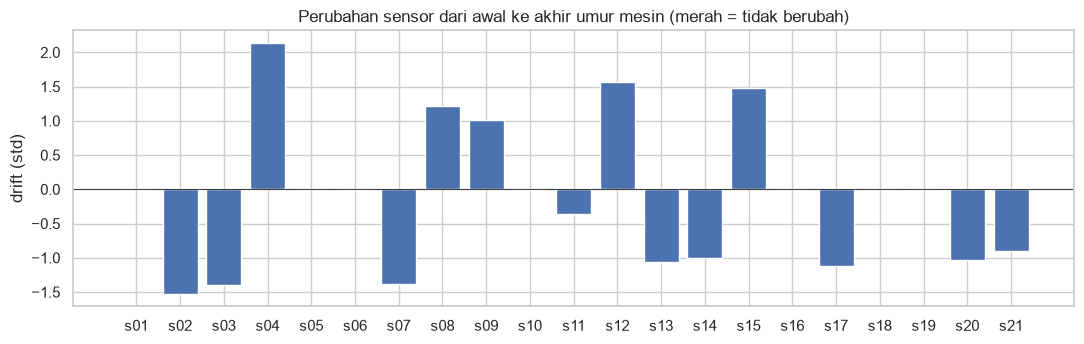

Kandidat sensor tidak informatif: ['s01', 's05', 's06', 's10', 's16', 's18', 's19']


In [31]:
pos   = train_df[CYCLE_COL] / train_df.groupby(ID_COL)[CYCLE_COL].transform("max")
early = Z[pos <= 0.2].groupby(train_df.loc[pos <= 0.2, ID_COL]).mean()
late  = Z[pos >= 0.8].groupby(train_df.loc[pos >= 0.8, ID_COL]).mean()
drift = (late - early).mean().rename("drift_awal_ke_akhir")     # satuan: std dalam-regime

sensor_tbl = pd.concat([drift, eta2], axis=1).assign(
    pct_nan=train_df[SENSORS].isna().mean() * 100,
    pct_spike=(Z.abs() > SPIKE_Z).mean() * 100).round(3)
sensor_tbl["kandidat_tidak_informatif"] = sensor_tbl["drift_awal_ke_akhir"].abs() < 0.05
print(sensor_tbl.sort_values("drift_awal_ke_akhir").to_string())

fig, ax = plt.subplots(figsize=(11, 3.6))
colors = ["#c44e52" if x else "#4c72b0" for x in sensor_tbl["kandidat_tidak_informatif"]]
ax.bar(sensor_tbl.index, sensor_tbl["drift_awal_ke_akhir"], color=colors)
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("drift (std)"); ax.set_title("Perubahan sensor dari awal ke akhir umur mesin (merah = tidak berubah)")
plt.tight_layout(); plt.show()
print("Kandidat sensor tidak informatif:", list(sensor_tbl.index[sensor_tbl["kandidat_tidak_informatif"]]))

**Interpretasi.** Tujuh sensor (**s01, s05, s06, s10, s16, s18, s19**) memiliki drift ≈ 0: nilainya tidak berubah dari awal sampai akhir umur mesin,
sehingga hanya berisi derau (dan spike, lihat 4.6). Sensor lain bergeser sistematis: sebagian **naik** saat mesin menua (s04, s12, s15, s08, s09) dan sebagian **turun**
(s02, s03, s07, s17, s13, s20, s14, s21). s11 berubah paling lemah. Pembuktian akhir memakai korelasi dengan RUL pada unit latih (Section 6).

## 4.5 Missing values

In [32]:
nan_pct = train_df[SENSORS].isna().mean() * 100
row_nan = train_df[SENSORS].isna().sum(axis=1).value_counts().sort_index()
print("NaN per sensor (%), train:"); print(nan_pct.round(2).to_string())
print("\nNaN per sensor (%), test min/max:", test_df[SENSORS].isna().mean().min().round(4) * 100, test_df[SENSORS].isna().mean().max().round(4) * 100)
print("\nJumlah sensor NaN per baris (train):", row_nan.to_dict())
print("Baris dengan >=1 NaN: %.1f%%" % (train_df[SENSORS].isna().any(axis=1).mean() * 100))
print("NaN pada kolom id_unit/siklus/setel:", int(train_df[[ID_COL, CYCLE_COL] + SETTINGS].isna().sum().sum()))

def nan_run_lengths(df, col):
    # panjang tiap run NaN berturut-turut dalam satu unit
    m = df[col].isna().to_numpy(); u = df[ID_COL].to_numpy()
    new = np.r_[True, (m[1:] != m[:-1]) | (u[1:] != u[:-1])]
    runs = pd.Series(m).groupby(np.cumsum(new)).agg(["first", "size"])
    return runs.loc[runs["first"], "size"]
run_len = pd.concat([nan_run_lengths(train_df, s) for s in SENSORS])
dist = run_len.value_counts().sort_index()
n_burst = int((run_len >= 6).sum())
print("Distribusi panjang run NaN (panjang: jumlah run):", dist.to_dict())
print(f"Run pendek (1-3 siklus): {int((run_len <= 3).sum())} | blok dropout (>=6 siklus): {n_burst}, terpanjang {int(run_len.max())} siklus"
      f" -> bacaan di blok panjang = {run_len[run_len >= 6].sum() / train_df[SENSORS].size * 100:.3f}% dari seluruh bacaan sensor")

phase = (pos * 10).clip(upper=9.99).astype(int)
print("\nRata-rata % NaN menurut fase umur (desil 0 = awal, 9 = akhir):")
print((train_df[SENSORS].isna().mean(axis=1).groupby(phase).mean() * 100).round(2).to_dict())

NaN per sensor (%), train:
s01    2.00
s02    2.07
s03    2.01
s04    2.05
s05    2.01
s06    2.06
s07    2.05
s08    2.02
s09    2.04
s10    2.02
s11    1.98
s12    2.04
s13    2.03
s14    1.99
s15    2.02
s16    2.00
s17    2.01
s18    2.06
s19    2.03
s20    2.11
s21    1.97

NaN per sensor (%), test min/max: 1.8900000000000001 2.1399999999999997

Jumlah sensor NaN per baris (train): {0: 165142, 1: 72223, 2: 14625, 3: 1982, 4: 189, 5: 13}
Baris dengan >=1 NaN: 35.0%
NaN pada kolom id_unit/siklus/setel: 0
Distribusi panjang run NaN (panjang: jumlah run): {1: 102718, 2: 2114, 3: 30, 6: 5, 7: 7, 8: 9, 9: 6, 10: 7, 11: 7, 12: 6, 13: 6, 14: 4, 15: 8, 16: 4, 17: 6, 18: 7, 19: 7, 20: 4, 21: 1}
Run pendek (1-3 siklus): 104862 | blok dropout (>=6 siklus): 94, terpanjang 21 siklus -> bacaan di blok panjang = 0.023% dari seluruh bacaan sensor

Rata-rata % NaN menurut fase umur (desil 0 = awal, 9 = akhir):
{0: 2.01, 1: 2.05, 2: 2.03, 3: 2.03, 4: 2.03, 5: 2.05, 6: 2.05, 7: 2.01, 8: 2.03, 9: 2.0}

**Interpretasi.** Sekitar **2% bacaan hilang di setiap sensor**, merata di semua sensor dan unit, serta **tidak bergantung pada fase umur mesin**
(tidak ada pola "hilang karena mau rusak"). Hampir semuanya titik tunggal acak (run 1-3 siklus, sesuai perkiraan hilang-acak independen), ditambah
**sekitar seratus blok dropout beruntun 6-21 siklus** yang sangat kecil porsinya (kira-kira 0,02% bacaan). Sekitar sepertiga baris punya minimal satu NaN, sehingga
**membuang baris tidak layak** (memutus kontinuitas deret waktu). Imputasi dengan **nilai valid terakhir (forward-fill per unit)** masuk akal dan **kausal**
(tidak memakai data masa depan); untuk blok panjang nilainya memang usang, tetapi dampaknya kecil karena langka. NaN di titik terakhir data uji juga ada (~2%), jadi pipeline harus menanganinya.

## 4.6 Sensor spikes
Spike didefinisikan dua cara: (a) nilai ternormalisasi regime dengan |z| > 5, dan (b) selisih lokal terhadap median bergulir 9 siklus dalam satu unit.

     pct_|z|>5  pct_lokal_>5  tidak_informatif
s16      0.213         0.197              True
s06      0.212         0.203              True
s05      0.206         0.194              True
s18      0.201         0.182              True
s10      0.199         0.183              True
s01      0.198         0.182              True
s19      0.197         0.188              True
s21      0.043         0.024             False
s17      0.029         0.000             False
s08      0.026         0.000             False
s09      0.025         0.001             False
s14      0.025         0.002             False
s20      0.024         0.000             False
s13      0.020         0.000             False
s07      0.015         0.001             False
s03      0.013         0.002             False
s15      0.013         0.000             False
s12      0.009         0.000             False
s02      0.006         0.000             False
s04      0.006         0.000             False
s11      0.00

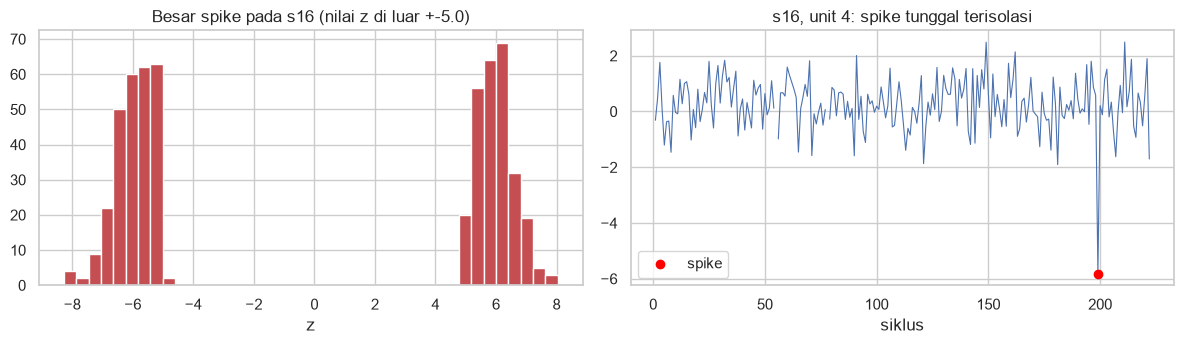

In [33]:
Zmed = Z.groupby(train_df[ID_COL]).transform(lambda x: x.rolling(9, center=True, min_periods=3).median())
spk_global = (Z.abs() > SPIKE_Z).mean() * 100
spk_local  = ((Z - Zmed).abs() > SPIKE_Z).mean() * 100
spk = pd.DataFrame({"pct_|z|>5": spk_global, "pct_lokal_>5": spk_local}).round(3)
spk["tidak_informatif"] = spk.index.isin(sensor_tbl.index[sensor_tbl["kandidat_tidak_informatif"]])
print(spk.sort_values("pct_|z|>5", ascending=False).to_string())

worst = spk["pct_|z|>5"].idxmax()
vals = Z[worst][Z[worst].abs() > SPIKE_Z]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(vals, bins=40, color="#c44e52"); ax[0].set_title(f"Besar spike pada {worst} (nilai z di luar +-{SPIKE_Z})"); ax[0].set_xlabel("z")
uid = train_df.loc[Z[worst].abs() > SPIKE_Z, ID_COL].iloc[0]; mu_ = train_df[ID_COL] == uid
ax[1].plot(train_df.loc[mu_, CYCLE_COL], Z.loc[mu_, worst], lw=0.8)
sp = mu_ & (Z[worst].abs() > SPIKE_Z); ax[1].scatter(train_df.loc[sp, CYCLE_COL], Z.loc[sp, worst], color="red", zorder=3, label="spike"); ax[1].legend()
ax[1].set_title(f"{worst}, unit {uid}: spike tunggal terisolasi"); ax[1].set_xlabel("siklus")
plt.tight_layout(); plt.show()

**Interpretasi.** Spike (±5–8 std) muncul pada sekitar **0,2% bacaan, dan hampir seluruhnya di tujuh sensor tidak informatif yang sama**
(s01, s05, s06, s10, s16, s18, s19). Spike berupa titik tunggal terisolasi, bukan perubahan level yang bertahan. Sensor informatif hampir bebas spike (≤ 0,05%).
Strategi: sensor tidak informatif dibuang; sebagai pengaman, titik dengan |z| > 5 pada sensor yang dipertahankan diperlakukan sebagai hilang lalu diimputasi kausal.

## 4.7 Visualisasi time-series
Tampilkan sensor informatif terhadap **siklus tersisa sampai rusak** (sumbu x dibalik: kanan = saat rusak) untuk beberapa unit.

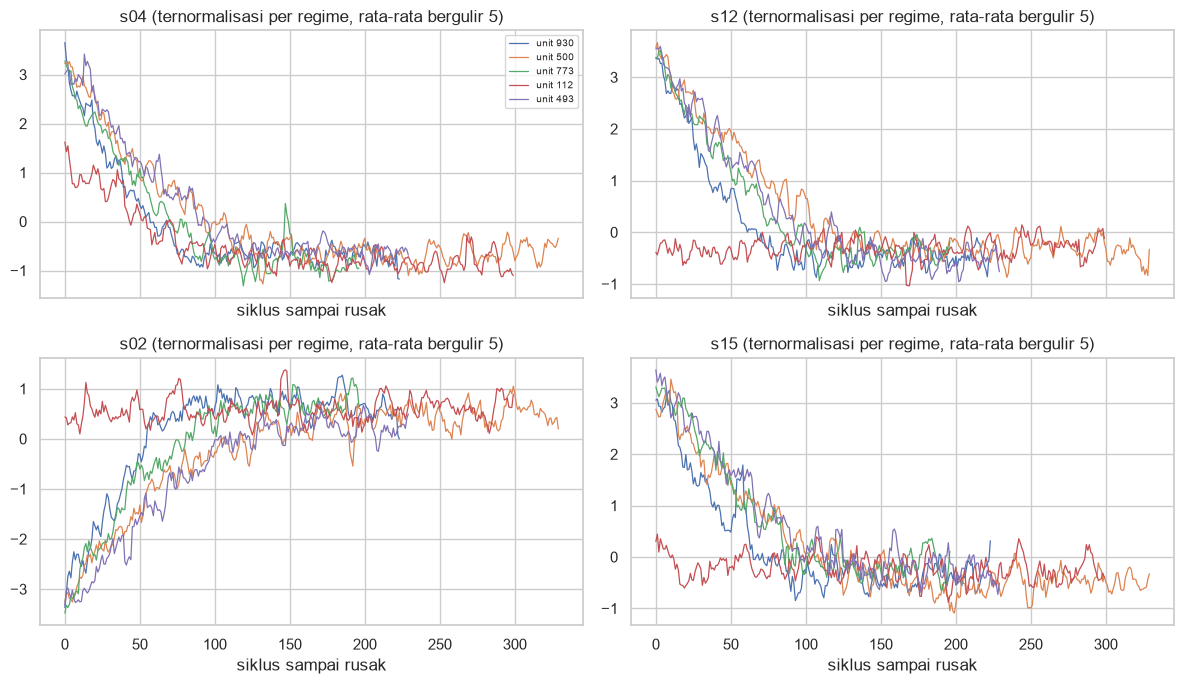

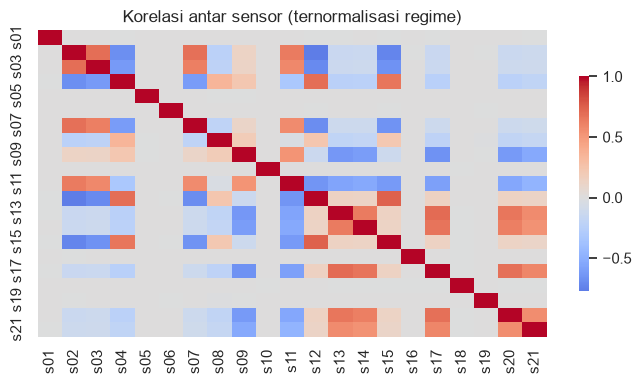

In [34]:
top_sensors = sensor_tbl["drift_awal_ke_akhir"].abs().sort_values(ascending=False).index[:4].tolist()
units_demo = np.random.default_rng(SEED).choice(train_df[ID_COL].unique(), 5, replace=False)
ttf = train_df.groupby(ID_COL)[CYCLE_COL].transform("max") - train_df[CYCLE_COL]     # siklus sampai rusak (EDA)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, s in zip(axes.ravel(), top_sensors):
    for u in units_demo:
        m = train_df[ID_COL] == u
        ax.plot(ttf[m], Z.loc[m, s].rolling(5, min_periods=1).mean(), lw=0.9, label=f"unit {u}")
    ax.invert_xaxis(); ax.set_title(f"{s} (ternormalisasi per regime, rata-rata bergulir 5)"); ax.set_xlabel("siklus sampai rusak")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(Z[[s for s in SENSORS]].corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Korelasi antar sensor (ternormalisasi regime)"); plt.tight_layout(); plt.show()

**Interpretasi.** Sensor informatif menunjukkan **tren monoton yang makin curam mendekati kerusakan**, tetapi dengan derau tinggi dan **laju degradasi
berbeda antar unit**. Ini mengisi dua kebutuhan desain: (1) satu pembacaan sesaat terlalu berderau, jadi perlu **jendela beberapa siklus** (sliding window);
(2) karena banyak sensor bergerak searah dan berkorelasi, gabungan sensor memberi sinyal yang lebih stabil daripada sensor tunggal.

# SECTION 5 — Data Preprocessing

Aturan anti-leakage yang dipegang di seluruh notebook:
* **Pembagian dilakukan per ID mesin** (bukan per baris) sebelum statistik apa pun dihitung.
* Pusat regime (KMeans), mean/std per regime, dan skala siklus **hanya dari unit latih**, lalu diterapkan ke validasi dan test.
* Imputasi memakai **forward-fill per unit** (hanya masa lalu). NaN di awal unit diisi 0 (= rata-rata regime setelah normalisasi).
* Data test tidak dipakai untuk tuning apa pun; ia hanya ditransformasi dengan statistik dari latih.

Urutan pipeline: split unit → fit regime & statistik pada unit latih → normalisasi per regime → spike dijadikan NaN → forward-fill → fitur akhir.

In [35]:
# ---- 5.1 Split berdasarkan ID unit (tidak boleh ada unit yang sama di train dan validasi) ----
all_units = np.sort(train_df[ID_COL].unique())
perm = np.random.default_rng(SEED).permutation(all_units)
n_val = int(round(VAL_FRAC * len(all_units)))
VAL_UNITS, TRAIN_UNITS = np.sort(perm[:n_val]), np.sort(perm[n_val:])
assert len(set(VAL_UNITS) & set(TRAIN_UNITS)) == 0
print(f"Unit latih: {len(TRAIN_UNITS)} | unit validasi: {len(VAL_UNITS)} | unit uji: {test_df[ID_COL].nunique()}")

fit_df = train_df[train_df[ID_COL].isin(TRAIN_UNITS)]      # SEMUA statistik di-fit hanya dari sini

# ---- 5.2 Regime operasi: KMeans pada setel_1..3 (fit hanya pada unit latih) ----
set_scaler = StandardScaler().fit(fit_df[SETTINGS])
kmeans = KMeans(n_clusters=N_REGIMES, n_init=10, random_state=SEED).fit(set_scaler.transform(fit_df[SETTINGS]))
def assign_regime(df):
    return kmeans.predict(set_scaler.transform(df[SETTINGS]))

fit_regime = assign_regime(fit_df)
print("\nPusat regime (skala asli):")
print(pd.DataFrame(set_scaler.inverse_transform(kmeans.cluster_centers_), columns=SETTINGS).round(2).assign(n_baris=np.bincount(fit_regime)))

# ---- 5.3 Mean/std sensor per regime (hanya unit latih; NaN diabaikan) ----
REG_MU = fit_df[SENSORS].groupby(fit_regime).mean()
REG_SD = fit_df[SENSORS].groupby(fit_regime).std()
SIKLUS_SCALE = float(fit_df[CYCLE_COL].max())               # untuk fitur umur (siklus) ternormalisasi
REGIME_COLS = [f"reg_{k}" for k in range(N_REGIMES)]

Unit latih: 720 | unit validasi: 180 | unit uji: 300

Pusat regime (skala asli):
   setel_1  setel_2  setel_3  n_baris
0     42.0     0.84    100.0    34487
1     10.0     0.25    100.0    33964
2     25.0     0.62     60.0    34118
3     20.0     0.70    100.0    34442
4      0.0     0.00    100.0    34216
5     35.0     0.84    100.0    34130


In [36]:
def preprocess(df, spike_z=SPIKE_Z):
    # Terapkan pipeline yang sudah di-fit ke df mana pun (train/val/test). Mengembalikan (df_baru, laporan).
    out = df.sort_values([ID_COL, CYCLE_COL]).reset_index(drop=True)
    reg = assign_regime(out)
    out["regime"] = reg
    for k in range(N_REGIMES):                                   # one-hot regime
        out[f"reg_{k}"] = (reg == k).astype(np.float32)

    raw = out[SENSORS].to_numpy(dtype=np.float64)
    z = (raw - REG_MU.loc[reg].to_numpy()) / REG_SD.loc[reg].to_numpy()   # normalisasi per regime
    n_nan_awal = int(np.isnan(z).sum())
    spike = np.abs(z) > spike_z
    n_spike = int(np.nansum(spike))
    z[spike] = np.nan                                            # spike dianggap bacaan hilang

    zdf = pd.DataFrame(z, columns=SENSORS)
    zdf[ID_COL] = out[ID_COL].to_numpy()
    zdf[SENSORS] = zdf.groupby(ID_COL)[SENSORS].ffill()          # forward-fill per unit (kausal)
    n_sisa = int(zdf[SENSORS].isna().sum().sum())                # NaN di awal unit
    out[SENSORS] = zdf[SENSORS].fillna(0.0).to_numpy()           # 0 = rata-rata regime

    out["siklus_norm"] = out[CYCLE_COL] / SIKLUS_SCALE
    return out, dict(nan_awal=n_nan_awal, spike=n_spike, nan_awal_unit=n_sisa)

train_pp, rep_tr = preprocess(train_df)
test_pp,  rep_te = preprocess(test_df)
print("Laporan train:", rep_tr); print("Laporan test :", rep_te)
assert train_pp[SENSORS].isna().sum().sum() == 0 and test_pp[SENSORS].isna().sum().sum() == 0

# Verifikasi: pada unit latih, sensor yang dipertahankan kini ber-mean ~0 dan std ~1 per regime
chk = train_pp[train_pp[ID_COL].isin(TRAIN_UNITS)][SENSORS]
print("\nRata-rata |mean| sensor (unit latih):", chk.mean().abs().mean().round(3), "| rata-rata std:", chk.std().mean().round(3))

Laporan train: {'nan_awal': 108240, 'spike': 4166, 'nan_awal_unit': 401}
Laporan test : {'nan_awal': 21711, 'spike': 777, 'nan_awal_unit': 140}

Rata-rata |mean| sensor (unit latih): 0.001 | rata-rata std: 0.986


**Catatan leakage.** Normalisasi memakai statistik unit latih saja; validasi dan test hanya *ditransformasi*. Forward-fill dilakukan dalam satu unit dan hanya melihat ke belakang,
sehingga nilai di siklus *t* tidak pernah bergantung pada siklus setelah *t*. Seleksi sensor (yang memakai label) dilakukan setelah label dibuat, di Section 6, juga hanya pada unit latih.

# SECTION 6 — RUL Labeling

Di data latih, siklus terakhir tiap unit adalah siklus saat rusak. Maka:

**RUL(t) = min( siklus_rusak − siklus(t), 150 )**

RUL pada siklus terakhir tiap unit == 0 : True
Min/Max RUL                              : 0.0 / 150.0
RUL tidak pernah naik dalam satu unit     : True
Penurunan per siklus hanya 0 (saat cap) atau 1: [np.float32(-1.0), np.float32(0.0)]

Contoh unit 3 (umur 318 siklus): 3 baris pertama dan 3 terakhir
 id_unit  siklus   rul
       3       1 150.0
       3       2 150.0
       3       3 150.0
       3     316   2.0
       3     317   1.0
       3     318   0.0


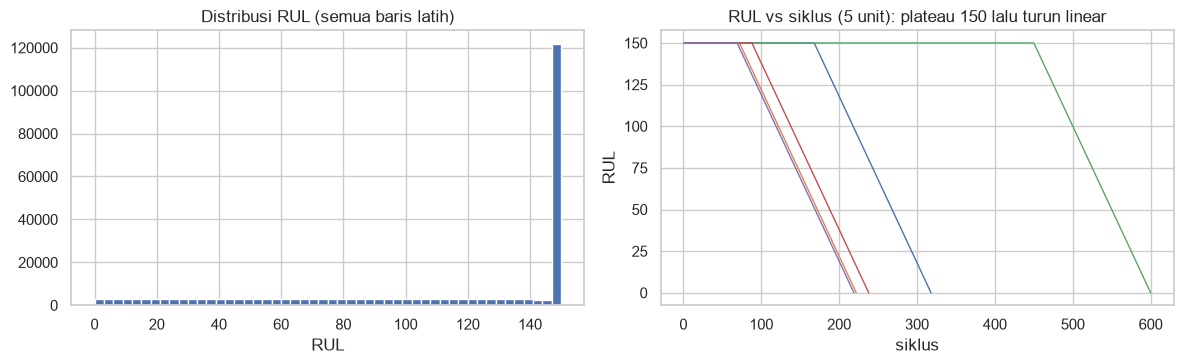

Porsi baris yang terkena cap (RUL = 150): 46.9%


In [37]:
def add_rul(df, cap=RUL_CAP):
    # RUL = sisa siklus sampai rusak (siklus terakhir unit), dipotong maksimal cap
    fail_cycle = df.groupby(ID_COL)[CYCLE_COL].transform("max")
    return (fail_cycle - df[CYCLE_COL]).clip(upper=cap).astype(np.float32)

train_pp["rul"] = add_rul(train_pp)

# ---- Verifikasi labeling ----
last = train_pp.groupby(ID_COL).tail(1)
print("RUL pada siklus terakhir tiap unit == 0 :", (last["rul"] == 0).all())
print("Min/Max RUL                              :", train_pp["rul"].min(), "/", train_pp["rul"].max())
step = train_pp.groupby(ID_COL)["rul"].diff().dropna()
print("RUL tidak pernah naik dalam satu unit     :", (step <= 0).all())
print("Penurunan per siklus hanya 0 (saat cap) atau 1:", sorted(step.unique()))
u = train_pp[ID_COL].iloc[0]; g = train_pp[train_pp[ID_COL] == u]
print(f"\nContoh unit {u} (umur {g[CYCLE_COL].max()} siklus): 3 baris pertama dan 3 terakhir")
print(pd.concat([g[[ID_COL, CYCLE_COL, "rul"]].head(3), g[[ID_COL, CYCLE_COL, "rul"]].tail(3)]).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(train_pp["rul"], bins=50, color="#4c72b0"); ax[0].set_title("Distribusi RUL (semua baris latih)"); ax[0].set_xlabel("RUL")
for uu in train_pp[ID_COL].unique()[:5]:
    gg = train_pp[train_pp[ID_COL] == uu]; ax[1].plot(gg[CYCLE_COL], gg["rul"], lw=1)
ax[1].set_title("RUL vs siklus (5 unit): plateau 150 lalu turun linear"); ax[1].set_xlabel("siklus"); ax[1].set_ylabel("RUL")
plt.tight_layout(); plt.show()
print("Porsi baris yang terkena cap (RUL = 150): %.1f%%" % ((train_pp["rul"] == RUL_CAP).mean() * 100))

**Interpretasi.** Label lolos semua pemeriksaan: RUL = 0 tepat di siklus rusak, turun 1 per siklus, dan datar di 150 pada fase awal umur mesin.
Hampir separuh baris latih berada di plateau 150, sehingga distribusi label **tidak seimbang** (menumpuk di 150). Ini realistis, karena fase
"sehat" memang panjang, tetapi berarti RMSE rata-rata bisa terlihat baik sekalipun prediksi di dekat kerusakan, yang paling kritis, kurang akurat. Karena itu
Section 13 menganalisis error per rentang RUL.

## 6.4 Seleksi fitur (hanya unit latih)
Sensor dipertahankan jika |korelasi Spearman dengan RUL| ≥ ambang. Dihitung pada unit latih saja agar validasi tetap bersih.

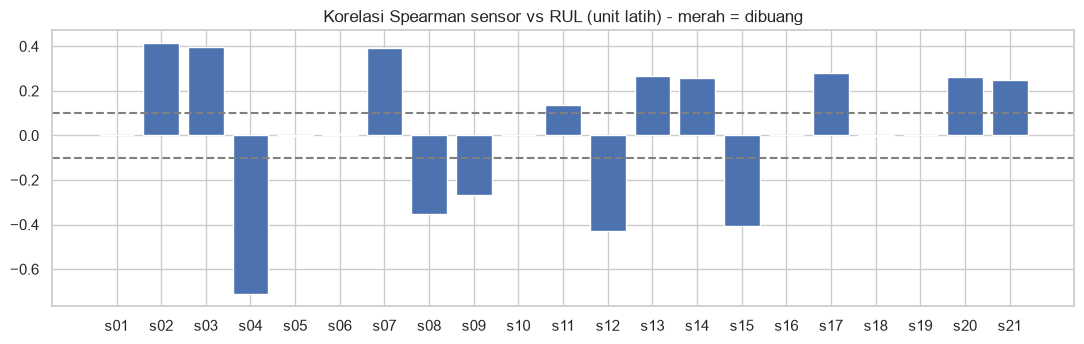

Dipertahankan (14): ['s02', 's03', 's04', 's07', 's08', 's09', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Dibuang      (7): ['s01', 's05', 's06', 's10', 's16', 's18', 's19']

Jumlah fitur akhir: 21 -> ['s02', 's03', 's04', 's07', 's08', 's09', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'reg_0', 'reg_1', 'reg_2', 'reg_3', 'reg_4', 'reg_5', 'siklus_norm']


In [38]:
fit_pp = train_pp[train_pp[ID_COL].isin(TRAIN_UNITS)]
rho = fit_pp[SENSORS].corrwith(fit_pp["rul"], method="spearman").rename("spearman_vs_RUL")
sel = rho.abs() >= SELECT_RHO
SELECTED_SENSORS = list(rho.index[sel]); DROPPED_SENSORS = list(rho.index[~sel])

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(rho.index, rho.values, color=["#4c72b0" if s else "#c44e52" for s in sel])
ax.axhline(SELECT_RHO, ls="--", c="gray"); ax.axhline(-SELECT_RHO, ls="--", c="gray")
ax.set_title("Korelasi Spearman sensor vs RUL (unit latih) - merah = dibuang"); plt.tight_layout(); plt.show()
print("Dipertahankan (%d):" % len(SELECTED_SENSORS), SELECTED_SENSORS)
print("Dibuang      (%d):" % len(DROPPED_SENSORS), DROPPED_SENSORS)

FEATURES = SELECTED_SENSORS + REGIME_COLS + ["siklus_norm"]       # fitur akhir model
print("\nJumlah fitur akhir:", len(FEATURES), "->", FEATURES)

**Interpretasi.** Hasil seleksi berbasis label menguatkan temuan EDA tanpa label: sensor yang tidak berubah sepanjang umur mesin
berkorelasi ≈ 0 dengan RUL dan dibuang, sisanya dipertahankan. Fitur akhir = sensor terpilih + one-hot regime (agar model tahu konteks operasi)
+ umur mesin (`siklus_norm`, tersedia juga di data uji karena `siklus` dihitung sejak mesin mulai dipakai).

# SECTION 7 — Sliding Window

Setiap sampel = **`SEQ_LEN` siklus terakhir** sampai siklus *t*, dengan label RUL pada siklus *t*. Untuk *t* < `SEQ_LEN`, bagian awal diisi
dengan **replikasi baris pertama unit** (*front-padding*) sehingga seluruh sampel berbentuk sama dan tidak ada informasi masa depan yang masuk.
Window tidak pernah melintasi batas unit.

`WindowSet` menyimpan data secara efisien (tanpa menggandakan memori untuk tiap window) dan membentuk batch `(B, SEQ_LEN, F)` saat dibutuhkan.

In [39]:
class WindowSet:
    # Kumpulan sliding window berbasis numpy. Satu window = SEQ_LEN baris berurutan (urut waktu) dari SATU unit.
    def __init__(self, df, features, seq_len, target_col=None, last_only=False, cap=RUL_CAP):
        df = df.sort_values([ID_COL, CYCLE_COL])
        self.L, self.features = seq_len, features
        blocks, cycs, starts, uids, cycles, ys = [], [], [], [], [], []
        offset = 0
        for uid, g in df.groupby(ID_COL, sort=True):
            x = g[features].to_numpy(np.float32); n = len(x); cyc = g[CYCLE_COL].to_numpy()
            blocks.append(np.vstack([np.repeat(x[:1], seq_len - 1, axis=0), x]))       # front-padding
            cycs.append(np.concatenate([np.full(seq_len - 1, -1), cyc]))               # -1 menandai padding
            t = np.array([n - 1]) if last_only else np.arange(n)                       # last_only: untuk prediksi test
            starts.append(offset + t); uids.append(np.full(len(t), uid)); cycles.append(cyc[t])
            if target_col is not None: ys.append(g[target_col].to_numpy(np.float32)[t])
            offset += n + seq_len - 1
        self.X = np.concatenate(blocks); self.C = np.concatenate(cycs)
        self.starts = np.concatenate(starts); self.unit_ids = np.concatenate(uids); self.cycles = np.concatenate(cycles)
        self.y = (np.concatenate(ys) / cap).astype(np.float32) if ys else None          # label diskalakan ke [0, 1]
        self._off = np.arange(seq_len)

    def __len__(self): return len(self.starts)

    def get(self, idx):
        idx = np.asarray(idx)
        win = self.X[self.starts[idx][:, None] + self._off]                            # (B, L, F)
        return win, (None if self.y is None else self.y[idx])

    def window_cycles(self, idx):
        return self.C[self.starts[np.asarray(idx)][:, None] + self._off]

    def batches(self, batch_size, shuffle=False, rng=None):
        order = np.arange(len(self))
        if shuffle: (rng or np.random.default_rng()).shuffle(order)
        for i in range(0, len(order), batch_size):
            yield self.get(order[i:i + batch_size])

train_sub = train_pp[train_pp[ID_COL].isin(TRAIN_UNITS)]
val_sub   = train_pp[train_pp[ID_COL].isin(VAL_UNITS)]

train_ds = WindowSet(train_sub, FEATURES, SEQ_LEN, target_col="rul")
val_ds   = WindowSet(val_sub,   FEATURES, SEQ_LEN, target_col="rul")
test_ds  = WindowSet(test_pp,   FEATURES, SEQ_LEN, last_only=True)      # satu window per unit uji (siklus terakhir)

F_DIM = len(FEATURES)
print(f"Tensor latih     : ({len(train_ds)}, {SEQ_LEN}, {F_DIM})  | y: ({len(train_ds)},)")
print(f"Tensor validasi  : ({len(val_ds)}, {SEQ_LEN}, {F_DIM})  | y: ({len(val_ds)},)")
print(f"Tensor test      : ({len(test_ds)}, {SEQ_LEN}, {F_DIM})  (1 window per unit uji)")
xb, yb = train_ds.get(np.arange(4)); print("Contoh batch      :", xb.shape, yb.shape, xb.dtype)

Tensor latih     : (205357, 30, 21)  | y: (205357,)
Tensor validasi  : (48817, 30, 21)  | y: (48817,)
Tensor test      : (300, 30, 21)  (1 window per unit uji)
Contoh batch      : (4, 30, 21) (4,) float32


In [40]:
# ---- Verifikasi urutan temporal & tidak ada kebocoran lintas unit ----
rng = np.random.default_rng(SEED)
ref = train_pp.set_index([ID_COL, CYCLE_COL])
for i in rng.choice(len(train_ds), 300, replace=False):
    wc = train_ds.window_cycles([i])[0]; real = wc[wc >= 0]
    assert (np.diff(real) == 1).all(), "siklus dalam window harus berurutan +1"
    assert real[-1] == train_ds.cycles[i], "baris terakhir window harus siklus ke-t"
    assert (wc[:SEQ_LEN - len(real)] == -1).all(), "padding hanya di depan"
    row = ref.loc[(train_ds.unit_ids[i], train_ds.cycles[i]), FEATURES].to_numpy(np.float32)
    assert np.allclose(train_ds.get([i])[0][0, -1], row), "baris terakhir window = fitur siklus ke-t"
print("OK: window berurutan, padding hanya di depan, baris terakhir = siklus t (300 sampel acak).")

# Unit tidak boleh bocor antar-split
assert not (set(train_ds.unit_ids) & set(val_ds.unit_ids))
assert not (set(train_ds.unit_ids) & set(test_ds.unit_ids)) and not (set(val_ds.unit_ids) & set(test_ds.unit_ids))
print("OK: unit latih / validasi / uji saling lepas.")

# Test: tiap unit uji harus tepat satu window, di siklus terakhirnya
cut_check = test_df.groupby(ID_COL)[CYCLE_COL].max()
assert (np.sort(test_ds.unit_ids) == np.sort(cut_check.index.values)).all()
assert (pd.Series(test_ds.cycles, index=test_ds.unit_ids).sort_index() == cut_check.sort_index()).all()
print("OK: window test = siklus terakhir tiap unit uji, jumlah =", len(test_ds))
print("Rentang RUL validasi:", val_ds.y.min() * RUL_CAP, "-", val_ds.y.max() * RUL_CAP, "| porsi di cap:", round(float((val_ds.y == 1).mean()), 3))

OK: window berurutan, padding hanya di depan, baris terakhir = siklus t (300 sampel acak).
OK: unit latih / validasi / uji saling lepas.
OK: window test = siklus terakhir tiap unit uji, jumlah = 300
Rentang RUL validasi: 0.0 - 150.0 | porsi di cap: 0.447


# SECTION 8 — Baseline Model (non-Deep Learning)

Baseline bekerja pada **fitur ringkasan tiap window**: nilai terakhir, rata-rata, standar deviasi, dan kemiringan (slope) setiap fitur dalam window.
Dua baseline: **Ridge Regression** (linear) dan **HistGradientBoosting** (pohon, non-linear).

**Metrik.**
* **RMSE** (dalam siklus).
* **Asymmetric score** (gaya NASA C-MAPSS), dengan `d = prediksi − aktual`: `exp(−d/a1) − 1` jika `d < 0` (prediksi terlalu cepat rusak) dan `exp(d/a2) − 1` jika `d ≥ 0` (prediksi terlalu optimistis, lebih berbahaya). **Lebih kecil = lebih baik.**

> ⚠️ **Cek ke PDF UTS:** konstanta `a1 = 13`, `a2 = 10` di bawah adalah konvensi standar C-MAPSS. Jika rumus pada instruksi dosen berbeda (konstanta atau arah d), ubah **hanya** parameter/rumus di fungsi `asymmetric_score` di cell berikut; seluruh notebook memakai fungsi ini.

In [41]:
# ---------------- Metrik (dipakai di seluruh notebook) ----------------
A1, A2 = 13.0, 10.0      # SESUAIKAN dengan rumus di PDF UTS jika berbeda

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

def asymmetric_score(y_true, y_pred, a1=A1, a2=A2):
    d = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    return float(np.sum(np.where(d < 0, np.exp(-d / a1) - 1.0, np.exp(d / a2) - 1.0)))

def mean_asym(y_true, y_pred):                 # versi rata-rata per sampel (agar dapat dibandingkan lintas ukuran data)
    return asymmetric_score(y_true, y_pred) / len(y_true)

RESULTS, VAL_PREDS, PRED_FN = {}, {}, {}       # RESULTS: tabel eksperimen | VAL_PREDS: prediksi validasi | PRED_FN: fungsi prediksi per model
Y_VAL = val_ds.y * RUL_CAP                     # label validasi dalam siklus

def register(name, y_pred, predict_fn):
    y_pred = np.clip(y_pred, 0, RUL_CAP)
    VAL_PREDS[name], PRED_FN[name] = y_pred, predict_fn
    RESULTS[name] = {"RMSE": rmse(Y_VAL, y_pred), "MAE": float(np.mean(np.abs(Y_VAL - y_pred))),
                     "Score": asymmetric_score(Y_VAL, y_pred), "Score/sampel": mean_asym(Y_VAL, y_pred)}
    print(f"{name:<22s} RMSE={RESULTS[name]['RMSE']:.3f} | MAE={RESULTS[name]['MAE']:.3f} | Score={RESULTS[name]['Score']:.1f} | Score/sampel={RESULTS[name]['Score/sampel']:.4f}")

# Sanity check metrik: prediksi sempurna -> 0; prediksi terlalu optimistis dihukum lebih berat daripada terlalu pesimistis
assert asymmetric_score([50], [50]) == 0 and rmse([50], [50]) == 0
assert asymmetric_score([50], [60]) > asymmetric_score([50], [40]) > 0
print("Sanity check metrik OK. Tebakan rata-rata RUL sebagai pembanding:", round(rmse(Y_VAL, np.full_like(Y_VAL, train_ds.y.mean() * RUL_CAP)), 2), "siklus RMSE")

Sanity check metrik OK. Tebakan rata-rata RUL sebagai pembanding: 49.5 siklus RMSE


In [42]:
def summarize_windows(win):
    # (N, L, F) -> fitur ringkasan (N, 4F): nilai terakhir, rata-rata, std, slope per fitur
    t = np.arange(win.shape[1], dtype=np.float32); t -= t.mean()
    slope = (win * t[None, :, None]).sum(1) / (t ** 2).sum()
    return np.concatenate([win[:, -1], win.mean(1), win.std(1), slope], axis=1)

def flat_features(ds, idx=None, chunk=20000):
    idx = np.arange(len(ds)) if idx is None else np.asarray(idx)
    return np.concatenate([summarize_windows(ds.get(idx[i:i + chunk])[0]) for i in range(0, len(idx), chunk)])

# Subsampel latih (stride 3) agar cepat; validasi memakai SEMUA window
tr_idx = np.arange(0, len(train_ds), 3)
X_tr_flat, y_tr_flat = flat_features(train_ds, tr_idx), train_ds.y[tr_idx] * RUL_CAP
X_va_flat = flat_features(val_ds)
print("Fitur ringkasan latih:", X_tr_flat.shape, "| validasi:", X_va_flat.shape)

# ---- Baseline 1: Ridge ----
ridge = Ridge(alpha=1.0).fit(X_tr_flat, y_tr_flat)
register("Baseline: Ridge", ridge.predict(X_va_flat),
         lambda ds, m=ridge: np.clip(m.predict(flat_features(ds)), 0, RUL_CAP))

# ---- Baseline 2: Gradient Boosting (tanpa early stopping internal agar tidak 'mengintip' baris latih acak) ----
t0 = time.time()
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, l2_regularization=1.0,
                                    early_stopping=False, random_state=SEED).fit(X_tr_flat, y_tr_flat)
register("Baseline: HistGB", hgb.predict(X_va_flat),
         lambda ds, m=hgb: np.clip(m.predict(flat_features(ds)), 0, RUL_CAP))
print(f"(HistGB dilatih dalam {time.time() - t0:.1f} dtk)")

Fitur ringkasan latih: (68453, 84) | validasi: (48817, 84)
Baseline: Ridge        RMSE=20.798 | MAE=15.479 | Score=1189195.2 | Score/sampel=24.3603
Baseline: HistGB       RMSE=18.025 | MAE=12.231 | Score=920014.6 | Score/sampel=18.8462
(HistGB dilatih dalam 13.4 dtk)


**Interpretasi baseline.** Pembanding paling naif (menebak rata-rata RUL untuk semua sampel) memberi RMSE besar; kedua baseline harus jauh di bawahnya.
Selisih Ridge vs HistGB menunjukkan seberapa non-linear hubungan sensor → RUL. Baseline ini menjadi **batas bawah yang harus dikalahkan** oleh model sekuens DL;
jika model DL tidak lebih baik dari baseline, kompleksitasnya tidak terjustifikasi.

# SECTION 9 — Deep Learning Model 1: LSTM

LSTM 2 lapis membaca window siklus demi siklus dan memakai *hidden state* terakhir untuk regresi RUL.

* **Loss:** MSE pada RUL yang diskalakan ke [0, 1] (selaras dengan RMSE sebagai metrik utama).
* **Optimizer:** AdamW (`weight_decay=1e-4`) + `ReduceLROnPlateau` + gradient clipping.
* **Regularisasi:** dropout + early stopping pada RMSE validasi.
* **Checkpoint:** bobot terbaik (RMSE validasi terendah) disimpan di `outputs/`.
* **Validasi** memakai unit yang tidak pernah dilihat saat training.

In [43]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_feat, hidden=96, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):                      # x: (B, L, F)
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)

def predict_dl(model, ds, batch_size=2048):
    # Prediksi deterministik (dropout mati), hasil dalam satuan siklus dan di-clip ke [0, RUL_CAP]
    model.eval(); outs = []
    with torch.no_grad():
        for xb, _ in ds.batches(batch_size):
            outs.append(model(torch.from_numpy(xb).to(DEVICE)).float().cpu().numpy())
    return np.clip(np.concatenate(outs), 0, 1) * RUL_CAP

def train_model(model, name, train_ds, val_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, patience=PATIENCE):
    model.to(DEVICE)
    criterion = nn.MSELoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    ckpt = OUTPUT_DIR / f"{name}_best.pt"
    rng = np.random.default_rng(SEED)
    y_val = val_ds.y * RUL_CAP
    hist = {"train_loss": [], "val_loss": [], "val_rmse": [], "lr": []}
    best, bad = float("inf"), 0

    for epoch in range(1, epochs + 1):
        model.train(); t0 = time.time(); run, n = 0.0, 0
        for xb, yb in train_ds.batches(batch_size, shuffle=True, rng=rng):
            xb, yb = torch.from_numpy(xb).to(DEVICE), torch.from_numpy(yb).to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                pred = model(xb)
            loss = criterion(pred.float(), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            run += loss.item() * len(xb); n += len(xb)

        pv = predict_dl(model, val_ds)
        v_rmse, v_loss = rmse(y_val, pv), float(np.mean((pv / RUL_CAP - val_ds.y) ** 2))
        sched.step(v_rmse)
        hist["train_loss"].append(run / n); hist["val_loss"].append(v_loss); hist["val_rmse"].append(v_rmse); hist["lr"].append(opt.param_groups[0]["lr"])
        flag = ""
        if v_rmse < best - 1e-4:
            best, bad = v_rmse, 0; torch.save(model.state_dict(), ckpt); flag = "  <- checkpoint"
        else:
            bad += 1
        print(f"[{name}] epoch {epoch:02d}/{epochs} | train_loss={run / n:.5f} | val_rmse={v_rmse:.3f} | lr={opt.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping (tidak membaik selama {patience} epoch)."); break

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))        # pakai bobot terbaik
    return model, hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(hist["train_loss"], label="train MSE"); ax[0].plot(hist["val_loss"], label="validasi MSE")
    ax[0].set(title=f"{title}: learning curve (MSE, skala 0-1)", xlabel="epoch"); ax[0].legend()
    ax[1].plot(hist["val_rmse"], color="#c44e52"); ax[1].axvline(int(np.argmin(hist["val_rmse"])), ls="--", c="gray")
    ax[1].set(title=f"{title}: RMSE validasi (siklus), terbaik = {min(hist['val_rmse']):.2f}", xlabel="epoch")
    plt.tight_layout(); plt.show()

MODELS, HISTORY = {}, {}

Parameter LSTM: 126,465
[LSTM] epoch 01/40 | train_loss=0.03278 | val_rmse=19.165 | lr=1.0e-03 | 200s  <- checkpoint
[LSTM] epoch 02/40 | train_loss=0.01713 | val_rmse=19.193 | lr=1.0e-03 | 189s
[LSTM] epoch 03/40 | train_loss=0.01549 | val_rmse=17.941 | lr=1.0e-03 | 199s  <- checkpoint
[LSTM] epoch 04/40 | train_loss=0.01451 | val_rmse=18.136 | lr=1.0e-03 | 192s
[LSTM] epoch 05/40 | train_loss=0.01352 | val_rmse=18.499 | lr=1.0e-03 | 204s
[LSTM] epoch 06/40 | train_loss=0.01272 | val_rmse=18.471 | lr=1.0e-03 | 201s
[LSTM] epoch 07/40 | train_loss=0.01187 | val_rmse=19.225 | lr=5.0e-04 | 200s
[LSTM] epoch 08/40 | train_loss=0.01081 | val_rmse=19.208 | lr=5.0e-04 | 191s
[LSTM] epoch 09/40 | train_loss=0.01017 | val_rmse=19.596 | lr=5.0e-04 | 167s
[LSTM] epoch 10/40 | train_loss=0.00960 | val_rmse=19.903 | lr=5.0e-04 | 199s
[LSTM] epoch 11/40 | train_loss=0.00894 | val_rmse=20.277 | lr=2.5e-04 | 152s
Early stopping (tidak membaik selama 8 epoch).


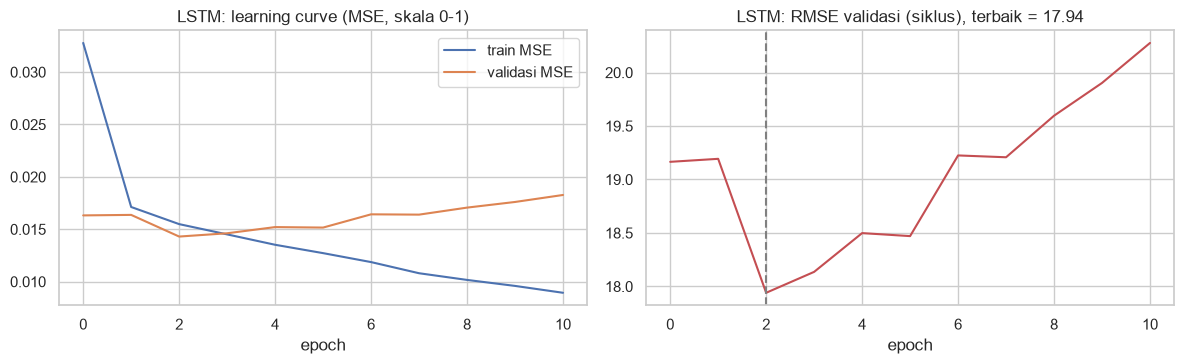

DL-1: LSTM             RMSE=17.941 | MAE=12.968 | Score=774830.7 | Score/sampel=15.8721


In [44]:
set_seed()
lstm = LSTMRegressor(F_DIM)
print(f"Parameter LSTM: {sum(p.numel() for p in lstm.parameters()):,}")
lstm, HISTORY["LSTM"] = train_model(lstm, "LSTM", train_ds, val_ds)
MODELS["LSTM"] = lstm
plot_history(HISTORY["LSTM"], "LSTM")
register("DL-1: LSTM", predict_dl(lstm, val_ds), lambda ds, m=lstm: predict_dl(m, ds))

**Interpretasi.** Perhatikan jarak antara kurva latih dan validasi: jika validasi mendatar atau naik sementara loss latih terus turun, model mulai *overfit* ke unit latih
(hanya mengingat lintasan degradasi unit tertentu). Early stopping dan dropout memitigasi hal ini. Bobot terbaik (RMSE validasi terendah) yang dipakai selanjutnya.

# SECTION 10 — Deep Learning Model 2: CNN-1D dengan konvolusi dilasi

Arsitektur berbeda dari LSTM: tiga lapis `Conv1d` dengan **dilasi 1, 2, 4** (receptive field mencakup seluruh window), lalu gabungan *global average pooling* dan fitur siklus terakhir.
Keunggulan: pelatihan paralel (lebih cepat dari LSTM) dan menangkap pola lokal (perubahan tren dalam beberapa siklus). Pipeline training, loss, optimizer, dan checkpoint sama dengan Model 1 agar perbandingannya adil.

Parameter CNN: 37,505
[CNN1D] epoch 01/40 | train_loss=0.02382 | val_rmse=18.858 | lr=1.0e-03 | 34s  <- checkpoint
[CNN1D] epoch 02/40 | train_loss=0.01636 | val_rmse=18.703 | lr=1.0e-03 | 32s  <- checkpoint
[CNN1D] epoch 03/40 | train_loss=0.01386 | val_rmse=20.473 | lr=1.0e-03 | 34s
[CNN1D] epoch 04/40 | train_loss=0.01150 | val_rmse=21.284 | lr=1.0e-03 | 22s
[CNN1D] epoch 05/40 | train_loss=0.00932 | val_rmse=20.672 | lr=1.0e-03 | 29s
[CNN1D] epoch 06/40 | train_loss=0.00778 | val_rmse=20.814 | lr=5.0e-04 | 33s
[CNN1D] epoch 07/40 | train_loss=0.00628 | val_rmse=20.721 | lr=5.0e-04 | 33s
[CNN1D] epoch 08/40 | train_loss=0.00585 | val_rmse=21.121 | lr=5.0e-04 | 31s
[CNN1D] epoch 09/40 | train_loss=0.00558 | val_rmse=22.018 | lr=5.0e-04 | 27s
[CNN1D] epoch 10/40 | train_loss=0.00544 | val_rmse=21.699 | lr=2.5e-04 | 24s
Early stopping (tidak membaik selama 8 epoch).


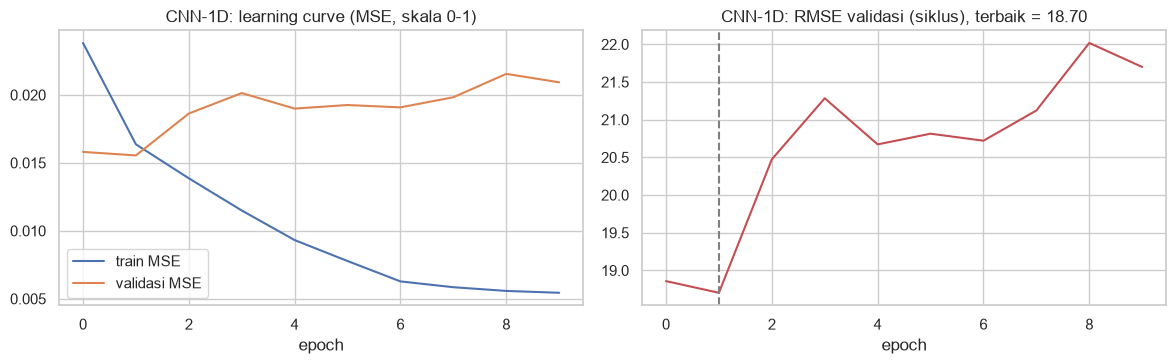

DL-2: CNN-1D           RMSE=18.703 | MAE=13.557 | Score=934723.1 | Score/sampel=19.1475


In [45]:
class CNNRegressor(nn.Module):
    def __init__(self, n_feat, channels=64, dropout=0.2):
        super().__init__()
        def block(cin, cout, dil):
            return nn.Sequential(nn.Conv1d(cin, cout, kernel_size=3, padding=dil, dilation=dil), nn.BatchNorm1d(cout), nn.ReLU())
        self.net = nn.Sequential(block(n_feat, channels, 1), block(channels, channels, 2), block(channels, channels, 4))
        self.head = nn.Sequential(nn.Linear(2 * channels, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):                           # x: (B, L, F) -> Conv1d butuh (B, F, L)
        h = self.net(x.transpose(1, 2))             # (B, C, L), panjang L dipertahankan oleh padding=dilasi
        feat = torch.cat([h.mean(-1), h[:, :, -1]], dim=1)      # rata-rata seluruh window + siklus terakhir
        return self.head(feat).squeeze(-1)

set_seed()
cnn = CNNRegressor(F_DIM)
print(f"Parameter CNN: {sum(p.numel() for p in cnn.parameters()):,}")
cnn, HISTORY["CNN1D"] = train_model(cnn, "CNN1D", train_ds, val_ds)
MODELS["CNN1D"] = cnn
plot_history(HISTORY["CNN1D"], "CNN-1D")
register("DL-2: CNN-1D", predict_dl(cnn, val_ds), lambda ds, m=cnn: predict_dl(m, ds))

**Interpretasi.** Bandingkan learning curve CNN dengan LSTM: kecepatan konvergensi, kestabilan validasi, dan celah latih-validasi. Perbedaan hasil kedua arsitektur
(dengan data, fitur, dan pipeline yang identik) mencerminkan perbedaan *inductive bias*: LSTM memodelkan dinamika berurutan, CNN menangkap pola lokal multi-skala.

# SECTION 11 — Model Comparison

Semua model dievaluasi pada **window validasi yang sama** (unit yang tidak dipakai untuk training/normalisasi/seleksi fitur). Data test tidak dipakai di sini.

                    RMSE     MAE        Score  Score/sampel
DL-1: LSTM        17.941  12.968   774830.676        15.872
Baseline: HistGB  18.025  12.231   920014.647        18.846
DL-2: CNN-1D      18.703  13.557   934723.142        19.147
Baseline: Ridge   20.798  15.479  1189195.222        24.360


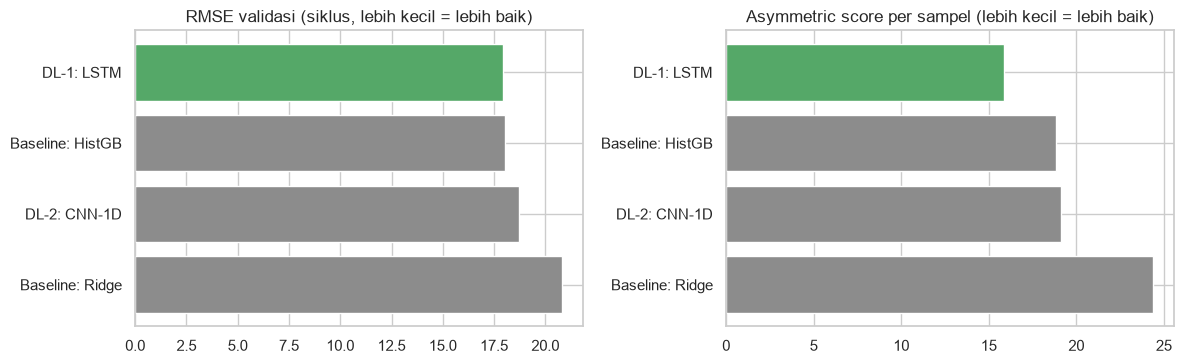

Model terbaik (RMSE): DL-1: LSTM | DL terbaik: DL-1: LSTM
Peringkat berdasarkan asymmetric score: ['DL-1: LSTM', 'Baseline: HistGB', 'DL-2: CNN-1D', 'Baseline: Ridge']


In [46]:
df_res = pd.DataFrame(RESULTS).T.sort_values("RMSE")
df_res.to_csv(OUTPUT_DIR / "hasil_eksperimen.csv")
BEST_NAME = df_res.index[0]
BEST_DL = min([n for n in df_res.index if n.startswith("DL")], key=lambda n: df_res.loc[n, "RMSE"])
display(df_res.style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "Score": "{:,.0f}", "Score/sampel": "{:.4f}"})
        .highlight_min(color="#c6efce", axis=0)) if "display" in globals() else print(df_res.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = ["#55a868" if n == BEST_NAME else "#8c8c8c" for n in df_res.index]
ax[0].barh(df_res.index, df_res["RMSE"], color=cols); ax[0].invert_yaxis(); ax[0].set_title("RMSE validasi (siklus, lebih kecil = lebih baik)")
ax[1].barh(df_res.index, df_res["Score/sampel"], color=cols); ax[1].invert_yaxis(); ax[1].set_title("Asymmetric score per sampel (lebih kecil = lebih baik)")
plt.tight_layout(); plt.show()
print(f"Model terbaik (RMSE): {BEST_NAME} | DL terbaik: {BEST_DL}")
print("Peringkat berdasarkan asymmetric score:", list(pd.DataFrame(RESULTS).T.sort_values('Score').index))

In [47]:
# Perbandingan prediksi per rentang RUL sebenarnya (apakah model unggul di dekat kerusakan, bukan hanya di plateau 150?)
bins = [-0.1, 25, 50, 100, 149.9, 150]; labels = ["0-25", "25-50", "50-100", "100-150", "=150 (cap)"]
bin_id = pd.cut(Y_VAL, bins=bins, labels=labels)
tab = pd.DataFrame({n: pd.Series((Y_VAL - VAL_PREDS[n]) ** 2).groupby(bin_id.astype(str)).mean().pow(0.5) for n in VAL_PREDS}).reindex(labels)
tab["n_sampel"] = pd.Series(bin_id.astype(str)).value_counts().reindex(labels)
print("RMSE per rentang RUL sebenarnya:"); print(tab.round(2).to_string())

RMSE per rentang RUL sebenarnya:
            Baseline: Ridge  Baseline: HistGB  DL-1: LSTM  DL-2: CNN-1D  n_sampel
0-25              15.400000             10.78       12.36     12.470000      4680
25-50             25.049999             16.63       17.18     17.490000      4500
50-100            32.169998             29.55       27.43     29.600000      9000
100-150           20.430000             20.88       20.51     20.790001      8815
=150 (cap)        13.850000             10.42       12.09     12.250000     21822


**Analisis model terbaik.** Pilih model dengan RMSE validasi terendah, tetapi periksa tiga hal sebelum menyimpulkan: (1) apakah modelnya juga unggul pada **asymmetric score**
(prediksi terlalu optimistis dihukum lebih berat, jadi model dengan RMSE sedikit lebih besar namun lebih konservatif bisa lebih aman); (2) apakah keunggulannya konsisten
**di dekat kerusakan** (rentang RUL kecil pada tabel di atas), bukan hanya di plateau 150; (3) apakah selisih antar-model cukup besar dibanding variasi antar-seed (satu seed saja = indikasi, bukan bukti).

# SECTION 12 — Uncertainty Estimation

Metode: **MC-Dropout.** Dropout dibiarkan aktif saat inferensi, model dijalankan `MC_SAMPLES` kali; rata-rata = prediksi, simpangan baku = ketidakpastian model (epistemik).
Karena std MC-Dropout biasanya **terlalu kecil** (interval kurang mencakup nilai sebenarnya), dilakukan **kalibrasi**:
unit validasi dibagi dua (kalibrasi vs evaluasi, terpisah per ID unit), lalu faktor pengali std dipilih agar cakupan di data kalibrasi = `INTERVAL_LEVEL`, dan dilaporkan pada data evaluasi.
Sebagai pembanding disertakan interval *split-conformal* berlebar tetap.

Dilakukan pada model DL terbaik dari Section 11.

In [48]:
def enable_mc_dropout(model):
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.Dropout, nn.LSTM)):     # BatchNorm tetap mode eval; LSTM train-mode hanya mengaktifkan dropout antar-lapis
            m.train()

def mc_predict(model, ds, T=MC_SAMPLES, batch_size=2048):
    enable_mc_dropout(model); passes = []
    with torch.no_grad():
        for _ in range(T):
            outs = [model(torch.from_numpy(xb).to(DEVICE)).float().cpu().numpy() for xb, _ in ds.batches(batch_size)]
            passes.append(np.clip(np.concatenate(outs), 0, 1) * RUL_CAP)
    model.eval()
    P = np.stack(passes); return P.mean(0), P.std(0)

best_key = "LSTM" if BEST_DL.endswith("LSTM") else "CNN1D"
mu_mc, sd_mc = mc_predict(MODELS[best_key], val_ds)
print(f"Model untuk uncertainty: {BEST_DL} | RMSE MC-mean = {rmse(Y_VAL, mu_mc):.3f} | rata-rata std MC = {sd_mc.mean():.2f} siklus")

# ---- Split unit validasi menjadi kalibrasi vs evaluasi (per ID unit, bukan per baris) ----
vu = np.random.default_rng(SEED + 1).permutation(VAL_UNITS)
calib_mask = np.isin(val_ds.unit_ids, vu[: len(vu) // 2]); eval_mask = ~calib_mask
z90 = {0.80: 1.2816, 0.90: 1.6449, 0.95: 1.96}[INTERVAL_LEVEL]
err = np.abs(Y_VAL - mu_mc)

k = np.quantile(err[calib_mask] / (sd_mc[calib_mask] + 1e-3), INTERVAL_LEVEL)    # pengali std terkalibrasi
q = np.quantile(err[calib_mask], INTERVAL_LEVEL)                                  # lebar tetap (split-conformal)
intervals = {
    f"MC mentah (±{z90:.2f} std)": (mu_mc - z90 * sd_mc, mu_mc + z90 * sd_mc),
    f"MC terkalibrasi (k={k:.2f})": (mu_mc - k * sd_mc, mu_mc + k * sd_mc),
    f"Conformal (±{q:.1f} siklus)": (mu_mc - q, mu_mc + q)}
rows = []
for nm, (lo, hi) in intervals.items():
    lo, hi = np.clip(lo, 0, RUL_CAP), np.clip(hi, 0, RUL_CAP)
    cover = (Y_VAL >= lo) & (Y_VAL <= hi)
    rows.append({"interval": nm, "target": INTERVAL_LEVEL, "cakupan (kalibrasi)": cover[calib_mask].mean(),
                 "cakupan (evaluasi)": cover[eval_mask].mean(), "lebar rata-rata (evaluasi)": (hi - lo)[eval_mask].mean()})
display(pd.DataFrame(rows).round(3)) if "display" in globals() else print(pd.DataFrame(rows).round(3))
LO, HI = [np.clip(a, 0, RUL_CAP) for a in intervals[f"MC terkalibrasi (k={k:.2f})"]]       # interval utama untuk visualisasi

Model untuk uncertainty: DL-1: LSTM | RMSE MC-mean = 18.104 | rata-rata std MC = 6.43 siklus
                   interval  target  cakupan (kalibrasi)  cakupan (evaluasi)  lebar rata-rata (evaluasi)
0     MC mentah (±1.64 std)     0.9                0.537               0.553                   19.093000
1  MC terkalibrasi (k=6.60)     0.9                0.900               0.913                   58.679001
2  Conformal (±29.2 siklus)     0.9                0.900               0.898                   46.340000


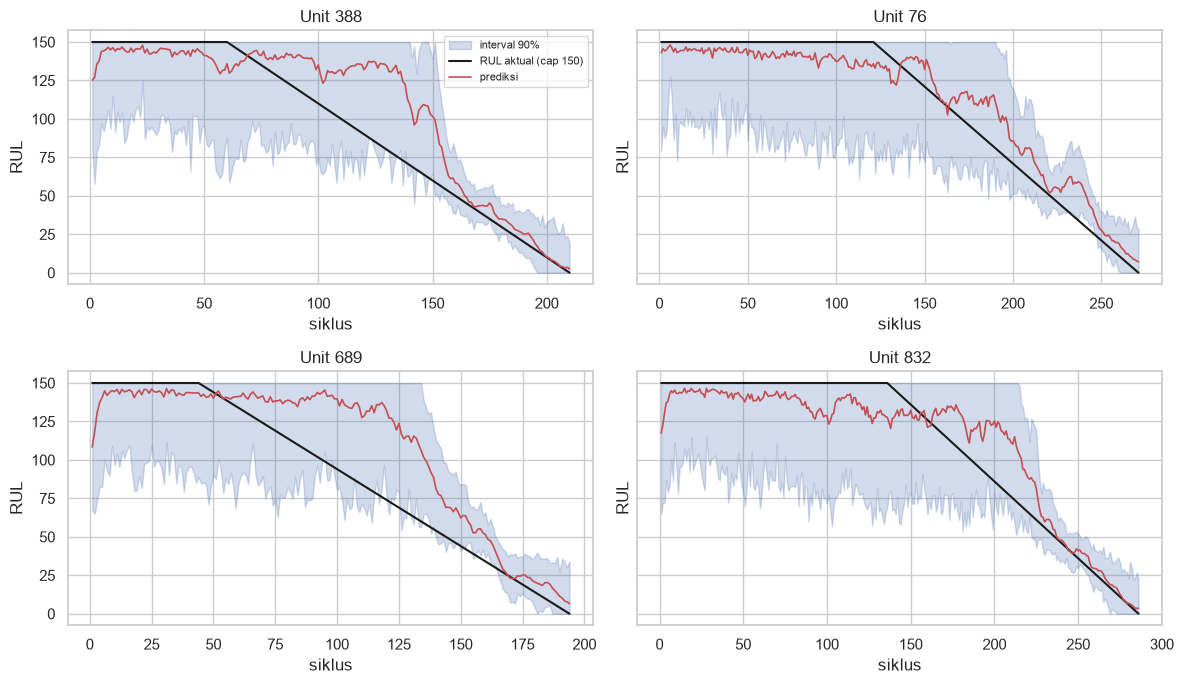

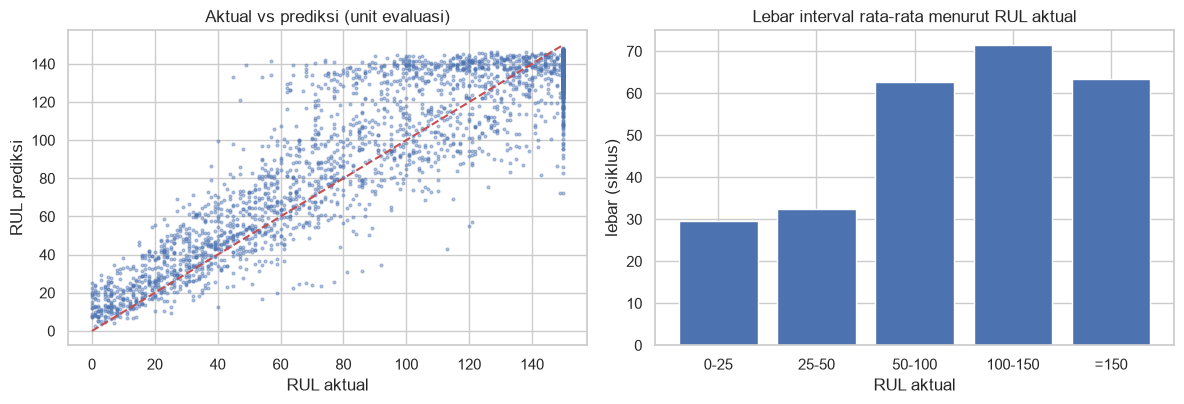

In [49]:
# ---- Visualisasi: aktual vs prediksi + interval, pada unit evaluasi ----
ev_units = np.unique(val_ds.unit_ids[eval_mask])
demo_units = np.random.default_rng(SEED).choice(ev_units, 4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, u in zip(axes.ravel(), demo_units):
    m = val_ds.unit_ids == u; c = val_ds.cycles[m]
    ax.fill_between(c, LO[m], HI[m], color="#4c72b0", alpha=0.25, label=f"interval {int(INTERVAL_LEVEL * 100)}%")
    ax.plot(c, Y_VAL[m], "k-", lw=1.5, label="RUL aktual (cap 150)"); ax.plot(c, mu_mc[m], color="#c44e52", lw=1.2, label="prediksi")
    ax.set(title=f"Unit {u}", xlabel="siklus", ylabel="RUL")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sub = np.random.default_rng(SEED).choice(np.where(eval_mask)[0], 4000, replace=False)
ax[0].scatter(Y_VAL[sub], mu_mc[sub], s=4, alpha=0.4); ax[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--")
ax[0].set(xlabel="RUL aktual", ylabel="RUL prediksi", title="Aktual vs prediksi (unit evaluasi)")
bid = pd.cut(Y_VAL[eval_mask], [-0.1, 25, 50, 100, 149.9, 150], labels=["0-25", "25-50", "50-100", "100-150", "=150"])
width = pd.Series((HI - LO)[eval_mask]).groupby(bid.astype(str)).mean().reindex(["0-25", "25-50", "50-100", "100-150", "=150"])
ax[1].bar(width.index, width.values, color="#4c72b0"); ax[1].set(title="Lebar interval rata-rata menurut RUL aktual", xlabel="RUL aktual", ylabel="lebar (siklus)")
plt.tight_layout(); plt.show()

**Penjelasan ketidakpastian.**
* Interval **MC mentah** biasanya *terlalu sempit* (cakupan di bawah target), sehingga model terlihat lebih yakin daripada seharusnya: MC-Dropout hanya menangkap ketidakpastian model,
  bukan derau sensor dan variasi laju degradasi antar-unit. Kalibrasi mengoreksinya, dan cakupan pada **unit evaluasi yang terpisah** menjadi ukuran jujurnya.
* Lebar interval **tidak seragam**: biasanya lebih lebar pada RUL besar (jauh dari kerusakan, tanda degradasi masih samar sehingga sulit dibedakan dari "sehat") dan menyempit mendekati kerusakan.
  Interval *conformal* berlebar tetap menjamin cakupan rata-rata tetapi tidak membedakan sampel yakin vs ragu, sedangkan interval MC terkalibrasi bersifat adaptif.
* Praktisnya, interval membantu keputusan perawatan: bila **batas bawah** interval sudah mendekati 0, mesin layak dijadwalkan perawatan meski titik prediksinya masih aman.

# SECTION 13 — Final Evaluation

Evaluasi model terbaik (berdasarkan RMSE validasi, Section 11) pada unit validasi.

In [50]:
pred_best = VAL_PREDS[BEST_NAME]
d = pred_best - Y_VAL                                  # d > 0: prediksi terlalu optimistis (mesin diprediksi lebih awet)
final = {"Model": BEST_NAME, "RMSE": rmse(Y_VAL, pred_best), "Asymmetric score": asymmetric_score(Y_VAL, pred_best),
         "Score/sampel": mean_asym(Y_VAL, pred_best), "MAE": float(np.abs(d).mean()), "Bias rata-rata (pred-aktual)": float(d.mean()),
         "% terlalu optimistis (d>0)": float((d > 0).mean() * 100)}
for kk, vv in final.items(): print(f"{kk:<30s}: {vv:.4f}" if isinstance(vv, float) else f"{kk:<30s}: {vv}")

# Simulasi protokol test: SATU titik acak per unit validasi, diulang 200 kali (sebagai pengganti satu undian test)
MIN_CUT = 50                                          # asumsi: titik potong acak minimal siklus ke-50
by_unit = {u: np.where((val_ds.unit_ids == u) & (val_ds.cycles >= MIN_CUT))[0] for u in VAL_UNITS}
by_unit = {u: ix for u, ix in by_unit.items() if len(ix)}
rr = np.random.default_rng(SEED + 7); sims = []
for _ in range(200):
    ix = np.array([rr.choice(v) for v in by_unit.values()]); sims.append((rmse(Y_VAL[ix], pred_best[ix]), asymmetric_score(Y_VAL[ix], pred_best[ix])))
sims = np.array(sims)
print(f"\nSimulasi 1 titik acak/unit (200x, {len(by_unit)} unit): RMSE = {sims[:, 0].mean():.2f} ± {sims[:, 0].std():.2f} | Score = {sims[:, 1].mean():,.0f} ± {sims[:, 1].std():,.0f}")

Model                         : DL-1: LSTM
RMSE                          : 17.9407
Asymmetric score              : 774830.6760
Score/sampel                  : 15.8721
MAE                           : 12.9676
Bias rata-rata (pred-aktual)  : 0.3960
% terlalu optimistis (d>0)    : 37.4501

Simulasi 1 titik acak/unit (200x, 180 unit): RMSE = 20.86 ± 1.25 | Score = 5,171 ± 3,133


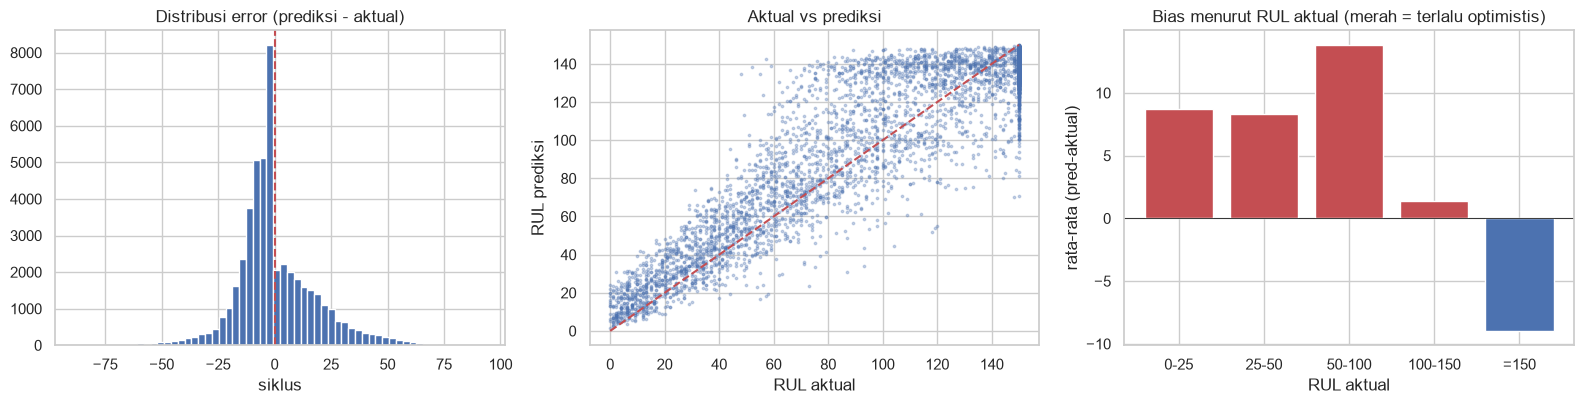

5 unit validasi dengan error rata-rata terbesar:
unit
217    38.51
941    33.06
55     29.67
600    29.32
993    27.74
Umur total unit tersebut (siklus): {217: 154, 941: 165, 55: 145, 600: 181, 993: 168}


In [51]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(d, bins=60, color="#4c72b0"); ax[0].axvline(0, c="r", ls="--"); ax[0].set(title="Distribusi error (prediksi - aktual)", xlabel="siklus")
sub = np.random.default_rng(SEED).choice(len(Y_VAL), 6000, replace=False)
ax[1].scatter(Y_VAL[sub], pred_best[sub], s=3, alpha=0.3); ax[1].plot([0, RUL_CAP], [0, RUL_CAP], "r--"); ax[1].set(title="Aktual vs prediksi", xlabel="RUL aktual", ylabel="RUL prediksi")
bid = pd.cut(Y_VAL, [-0.1, 25, 50, 100, 149.9, 150], labels=["0-25", "25-50", "50-100", "100-150", "=150"])
bias = pd.Series(d).groupby(bid.astype(str)).mean().reindex(["0-25", "25-50", "50-100", "100-150", "=150"])
ax[2].bar(bias.index, bias.values, color=["#c44e52" if v > 0 else "#4c72b0" for v in bias.values]); ax[2].axhline(0, c="k", lw=0.6)
ax[2].set(title="Bias menurut RUL aktual (merah = terlalu optimistis)", xlabel="RUL aktual", ylabel="rata-rata (pred-aktual)")
plt.tight_layout(); plt.show()

# Unit dengan error terbesar
unit_err = pd.DataFrame({"unit": val_ds.unit_ids, "abs_err": np.abs(d)}).groupby("unit").abs_err.mean().sort_values(ascending=False)
print("5 unit validasi dengan error rata-rata terbesar:"); print(unit_err.head(5).round(2).to_string())
print("Umur total unit tersebut (siklus):", train_df.groupby(ID_COL)[CYCLE_COL].max().loc[unit_err.index[:5]].to_dict())

**Analisis kesalahan prediksi.** Pola yang perlu dibaca dari grafik di atas:
* **Bias menurut RUL:** model regresi cenderung *menarik prediksi ke tengah* (terlalu rendah saat RUL aktual tinggi, terlalu tinggi saat RUL aktual rendah). Bar merah di rentang RUL rendah
  berarti model terlalu optimistis menjelang rusak, kesalahan yang paling dihukum oleh asymmetric score.
* **Plateau 150:** sampel dengan RUL aktual 150 tampak "sehat" (belum ada tren) sehingga prediksi tersebar di bawah 150; ini batas informasi data, bukan sekadar kelemahan model.
* **Unit sulit:** unit dengan error terbesar biasanya mempunyai laju degradasi atipikal (sangat panjang atau sangat pendek umurnya) sehingga polanya jarang dalam data latih.
* **Protokol test:** karena test hanya memakai satu titik acak per unit, skor sangat bervariasi antar-undian; angka simulasi di atas (rata-rata ± std) lebih jujur daripada satu angka tunggal.

# SECTION 14 — Test Prediction

Prediksi dibuat pada **siklus terakhir tiap unit uji** menggunakan model terbaik. Data test hanya melalui `preprocess()` (statistik dari unit latih), tanpa dipakai untuk tuning apa pun.

Model: DL-1: LSTM | jumlah prediksi = 300 (= jumlah unit uji 300) | urutan id_unit menaik: OK
count    300.00
mean      94.20
std       44.05
min        5.18
25%       55.08
50%      108.89
75%      136.64
max      147.56


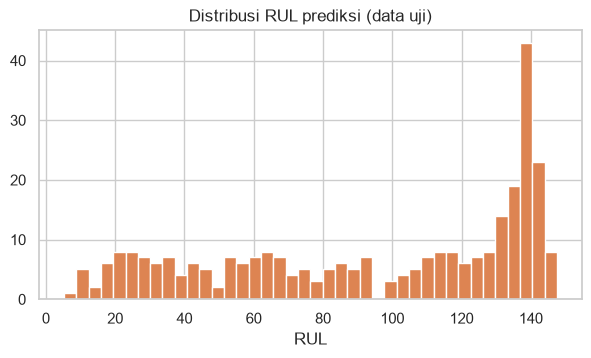

In [52]:
pred_test = PRED_FN[BEST_NAME](test_ds)                # urutan = unit_id menaik (WindowSet mengurutkan per id_unit)
pred_test = np.clip(pred_test, 0, RUL_CAP)
test_ids = test_ds.unit_ids

# ---- Pemeriksaan wajib ----
expected_ids = np.sort(test_df[ID_COL].unique())
assert len(pred_test) == test_df[ID_COL].nunique(), "jumlah prediksi harus = jumlah unit uji"
assert (test_ids == expected_ids).all(), "urutan/kumpulan id_unit tidak sesuai"
assert len(np.unique(test_ids)) == len(test_ids), "id_unit harus unik"
assert np.isfinite(pred_test).all(), "ada prediksi NaN/inf"
assert (test_ds.cycles == test_df.groupby(ID_COL)[CYCLE_COL].max().loc[test_ids].to_numpy()).all(), "window bukan siklus terakhir"
print(f"Model: {BEST_NAME} | jumlah prediksi = {len(pred_test)} (= jumlah unit uji {test_df[ID_COL].nunique()}) | urutan id_unit menaik: OK")
print(pd.Series(pred_test).describe().round(2).to_string())
plt.figure(figsize=(7, 3.5)); plt.hist(pred_test, bins=40, color="#dd8452"); plt.title("Distribusi RUL prediksi (data uji)"); plt.xlabel("RUL"); plt.show()

# SECTION 15 — Export CSV

Berkas `prediksi_rul.csv` dengan kolom **`id_unit, rul`**, satu baris per unit uji.

In [53]:
submission = pd.DataFrame({"id_unit": test_ids.astype(int), "rul": np.round(pred_test, 2)})
submission.to_csv(CSV_NAME, index=False)                       # di working directory (Colab: /content/prediksi_rul.csv)
submission.to_csv(OUTPUT_DIR / CSV_NAME, index=False)          # salinan di outputs/

# Baca ulang & validasi format
chk = pd.read_csv(CSV_NAME)
assert list(chk.columns) == ["id_unit", "rul"] and len(chk) == test_df[ID_COL].nunique()
assert chk["id_unit"].is_unique and set(chk["id_unit"]) == set(test_df[ID_COL]) and chk["rul"].between(0, RUL_CAP).all() and not chk.isna().any().any()
print(f"Tersimpan: {Path(CSV_NAME).resolve()}  ({len(chk)} baris)"); print(chk.head())

# Simpan juga ringkasan eksperimen
import json
with open(OUTPUT_DIR / "ringkasan.json", "w") as f:
    json.dump({"model_terbaik": BEST_NAME, "seq_len": SEQ_LEN, "fitur": FEATURES, "hasil_validasi": RESULTS}, f, indent=2)

try:                                                            # unduh otomatis jika di Colab
    from google.colab import files
    files.download(CSV_NAME)
except ImportError:
    pass

Tersimpan: D:\TELKOM\Semester 7\DL\UTS\kode\prediksi_rul.csv  (300 baris)
   id_unit     rul
0        1   59.51
1        2   34.30
2        6  103.37
3        8  142.40
4       16   39.27


# SECTION 16 — Conclusion

In [54]:
b = RESULTS[BEST_NAME]; base_best = min((n for n in RESULTS if n.startswith("Baseline")), key=lambda n: RESULTS[n]["RMSE"])
gain = (1 - b["RMSE"] / RESULTS[base_best]["RMSE"]) * 100
print(f"Model terbaik        : {BEST_NAME}  (RMSE validasi {b['RMSE']:.2f} siklus, asymmetric score {b['Score']:,.0f}, per sampel {b['Score/sampel']:.3f})")
print(f"Baseline terbaik     : {base_best}  (RMSE {RESULTS[base_best]['RMSE']:.2f})")
print(f"Selisih RMSE vs baseline terbaik: {gain:+.1f}% ({'model terbaik lebih baik' if gain > 0 else 'baseline lebih baik atau setara'})")
print(f"Pembanding naif (tebak rata-rata): RMSE {rmse(Y_VAL, np.full_like(Y_VAL, train_ds.y.mean() * RUL_CAP)):.2f}")

Model terbaik        : DL-1: LSTM  (RMSE validasi 17.94 siklus, asymmetric score 774,831, per sampel 15.872)
Baseline terbaik     : Baseline: HistGB  (RMSE 18.03)
Selisih RMSE vs baseline terbaik: +0.5% (model terbaik lebih baik)
Pembanding naif (tebak rata-rata): RMSE 49.50


## Kesimpulan

**Hasil.** Pipeline lengkap (EDA → preprocessing anti-leakage → label RUL cap 150 → sliding window per unit → baseline vs LSTM vs CNN-1D → interval prediksi → prediksi test)
menghasilkan `prediksi_rul.csv` berisi satu prediksi RUL per unit uji. Angka RMSE dan asymmetric score model terbaik dicetak otomatis di cell di atas dan tercatat pada
`outputs/hasil_eksperimen.csv`, sehingga kesimpulan angka selalu sesuai dengan hasil run terakhir.

**Insight dari data.**
1. **Regime operasi adalah faktor dominan:** 6 kombinasi pengaturan operasi menjelaskan sebagian besar variasi sensor mentah; tanpa normalisasi per regime, sinyal degradasi tertutup.
2. **Tujuh sensor adalah derau murni** (tidak berubah sepanjang umur mesin) dan sekaligus menjadi sumber hampir semua spike; membuangnya menyederhanakan model tanpa kehilangan informasi.
3. **Data hilang (~2%) bersifat acak** dan independen dari fase umur, sehingga forward-fill kausal per unit sudah memadai.
4. **Label tidak seimbang** (hampir separuh di plateau 150), sehingga RMSE global perlu dilengkapi analisis per rentang RUL.

**Kelebihan pendekatan.** Pembagian per ID unit dan statistik hanya dari unit latih mencegah leakage; metrik, label, dan prediksi memakai satu pipeline yang sama untuk latih/validasi/test;
interval prediksi dikalibrasi pada unit terpisah sehingga klaim cakupannya jujur; baseline non-DL memberi tolok ukur yang objektif bagi model DL.

**Keterbatasan.**
* Satu seed dan satu pembagian train/validasi: selisih kecil antar-model belum tentu signifikan (perlu beberapa seed / cross-validation per unit).
* Model akhir tidak dilatih ulang pada gabungan latih+validasi; menambah 20% unit berpotensi sedikit memperbaiki hasil.
* `SEQ_LEN` dan hyperparameter tidak di-tuning secara ekstensif (waktu komputasi); asymmetric score tidak dipakai langsung sebagai loss.
* Interval MC-Dropout hanya menangkap ketidakpastian model; kalibrasi memperbaiki cakupan rata-rata tetapi tidak menjamin cakupan per-sampel.
* Validasi memakai semua siklus, sedangkan test hanya satu titik acak per unit; simulasi di Section 13 membantu tetapi bukan pengganti.

**Langkah lanjutan.** Ensemble beberapa seed/arsitektur, loss yang sadar-asimetri (hukuman lebih besar untuk prediksi terlalu optimistis), tuning `SEQ_LEN`, dan model Transformer/TCN yang lebih dalam.